# EGFR Machine-Learning Algorithm Comparison

A complete, reproducible comparison of **XGBoost, Random Forest (RF), Linear SVM (LSVM), a genuine Radial Basis Function Network (RBFN), and Bernoulli Naive Bayes (NB)** on the project EGFR bioactivity dataset. The target is EGFR / UniProt **P00533**; labels are Active (1) and Inactive (0).

The notebook validates and canonicalizes SMILES, consolidates duplicate structures, removes structures with conflicting activity labels, computes radius-2 2048-bit Morgan fingerprints, and uses a stratified group-aware holdout split. Every chart is derived from the dataset or trained model outputs, displayed in the notebook, and saved as a 300-DPI PNG. Training imbalance is handled with balanced sample weights; the test set keeps the natural class distribution.

**Duplicate-label policy:** repeated records of the same canonical structure with unanimous labels are consolidated into one molecule. Structures with both Active and Inactive records are excluded rather than assigned an arbitrary label. Group-aware splitting is retained and overlap is asserted even after consolidation.

## 1. Introduction and reproducibility

This notebook expects `data/processed/preprocessed_source_records.csv` in this repository. Outputs are written beneath the repository root: `EGFR_model_evaluation_plots/`, `EGFR_model_artifacts/`, and summary CSV/JSON files. The dependency check below reports missing packages instead of silently substituting a different implementation. Use a Python kernel that has pandas, NumPy, RDKit, scikit-learn, XGBoost, Matplotlib, Seaborn, SciPy, and joblib installed.

The repository `.venv` is missing Seaborn. To run with that interpreter, install it with `.venv/bin/python -m pip install seaborn`, or select the Python 3.13 environment used to execute and validate this notebook. `nbformat`/`nbclient` are also absent from `.venv`; these are notebook tooling packages, not model runtime requirements.

In [1]:
import json
import platform
import sys
import time
import warnings
from pathlib import Path

required_packages = {
    "pandas": "pandas",
    "numpy": "numpy",
    "rdkit": "rdkit",
    "sklearn": "scikit-learn",
    "xgboost": "xgboost",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "scipy": "scipy",
    "joblib": "joblib",
}
missing_packages = []
for module_name, package_name in required_packages.items():
    try:
        __import__(module_name)
    except ImportError:
        missing_packages.append(package_name)
if missing_packages:
    raise ImportError(
        "Missing notebook dependencies: " + ", ".join(missing_packages)
        + ". Install them in this notebook kernel, then rerun the notebook."
    )

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from rdkit import Chem, RDLogger
from rdkit.Chem import rdFingerprintGenerator
from scipy.sparse import csr_matrix
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.calibration import calibration_curve
from sklearn.cluster import MiniBatchKMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    matthews_corrcoef,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedGroupKFold, StratifiedShuffleSplit
from sklearn.naive_bayes import BernoulliNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics.pairwise import euclidean_distances
from xgboost import XGBClassifier

warnings.filterwarnings("ignore", category=UserWarning, module="xgboost")
RDLogger.DisableLog("rdApp.error")

SEED = 42
TARGET_UNIPROT = "P00533"
TARGET_NAME = "EGFR"
N_BITS = 2048
MORGAN_RADIUS = 2
TEST_FRACTION = 0.20
N_SPLITS = 5
MODEL_NAMES = ["XGBoost", "Random Forest", "Linear SVM", "RBF Network", "Naive Bayes"]

sns.set_theme(style="whitegrid", context="notebook", font_scale=1.0)
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300, "axes.titlesize": 13, "axes.labelsize": 11})

# Find the repository root regardless of whether Jupyter started in the root or notebooks/.
search_locations = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
PROJECT_ROOT = next(
    (location for location in search_locations
     if (location / "data" / "processed" / "preprocessed_source_records.csv").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate data/processed/preprocessed_source_records.csv from the current directory."
    )
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "preprocessed_source_records.csv"
PLOT_DIR = PROJECT_ROOT / "EGFR_model_evaluation_plots"
ARTIFACT_DIR = PROJECT_ROOT / "EGFR_model_artifacts"
MODEL_DIR = ARTIFACT_DIR / "models"
for output_dir in (PLOT_DIR, MODEL_DIR):
    output_dir.mkdir(parents=True, exist_ok=True)

print(f"Python: {platform.python_version()}")
print(f"Project root: {PROJECT_ROOT}")
print(f"Dataset: {DATA_PATH}")
print(f"Plots: {PLOT_DIR}")
print(f"Models and metadata: {ARTIFACT_DIR}")

Python: 3.13.5
Project root: /Users/m.saikarthikeya/Desktop/XGBioactiveNew
Dataset: /Users/m.saikarthikeya/Desktop/XGBioactiveNew/data/processed/preprocessed_source_records.csv
Plots: /Users/m.saikarthikeya/Desktop/XGBioactiveNew/EGFR_model_evaluation_plots
Models and metadata: /Users/m.saikarthikeya/Desktop/XGBioactiveNew/EGFR_model_artifacts


## 2. Dataset loading

Load the actual processed CSV and inspect its shape, columns, missingness, and label distribution. The processed file does not carry a target-accession column, so when the raw source file is present the notebook verifies that its target metadata contains only P00533. If a target column is present in the processed file, it is checked directly.

In [2]:
df_source = pd.read_csv(DATA_PATH)
print("Shape:", df_source.shape)
print("Columns:", df_source.columns.tolist())
print("Missing values by column:")
display(df_source.isna().sum().to_frame("missing_count"))

required_columns = {"Molecule ChEMBL ID", "Smiles", "Activity"}
missing_columns = required_columns.difference(df_source.columns)
if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {sorted(missing_columns)}")

if "target_uniprot" in df_source.columns:
    observed_targets = set(df_source["target_uniprot"].dropna().astype(str).str.strip().str.upper())
    if observed_targets != {TARGET_UNIPROT}:
        raise ValueError(f"Expected only {TARGET_UNIPROT}; found {sorted(observed_targets)}")
    print(f"Verified target column: {TARGET_UNIPROT}")
else:
    raw_source_path = PROJECT_ROOT / "data" / "raw" / "source_records.csv"
    if raw_source_path.is_file():
        raw_targets = pd.read_csv(raw_source_path, usecols=["target_uniprot"])["target_uniprot"]
        observed_targets = set(raw_targets.dropna().astype(str).str.strip().str.upper())
        if observed_targets != {TARGET_UNIPROT}:
            raise ValueError(
                f"Raw source target metadata is not exclusively {TARGET_UNIPROT}: {sorted(observed_targets)}"
            )
        print(f"Verified raw-source target metadata: {TARGET_UNIPROT} (EGFR)")
    else:
        print("Target accession is not a processed-file column and raw source metadata is unavailable.")

print("\nRaw class distribution:")
display(df_source["Activity"].astype(str).str.strip().value_counts(dropna=False).rename_axis("Activity").to_frame("records"))

Shape: (25179, 6)
Columns: ['Molecule ChEMBL ID', 'Smiles', 'Standard Type', 'Standard Value', 'Standard Units', 'Activity']
Missing values by column:


,missing_count
Molecule ChEMBL ID,0
Smiles,0
Standard Type,0
Standard Value,0
Standard Units,0
Activity,0


Verified raw-source target metadata: P00533 (EGFR)



Raw class distribution:


,records
Activity,
Active,21468
Inactive,3711


## 3. Preprocessing

Drop exact duplicate rows, normalize the two expected class labels, parse each SMILES with RDKit, and generate canonical isomeric SMILES. Invalid structures are removed. Records are then grouped by canonical structure: unanimous groups become one training example, while conflicting-label structures are excluded and counted. This prevents the same molecule from appearing under multiple labels.

In [3]:
records = df_source.drop_duplicates().copy()
records["Activity"] = records["Activity"].astype(str).str.strip().str.lower()
label_map = {"active": 1, "inactive": 0, "1": 1, "0": 0}
records["label"] = records["Activity"].map(label_map)
unknown_labels = sorted(records.loc[records["label"].isna(), "Activity"].unique().tolist())
if unknown_labels:
    raise ValueError(f"Unrecognized Activity labels: {unknown_labels}")
records["label"] = records["label"].astype(np.int8)

canonical_smiles = []
valid_molecules = []
for smiles in records["Smiles"].fillna("").astype(str):
    molecule = Chem.MolFromSmiles(smiles)
    if molecule is None:
        canonical_smiles.append(None)
        valid_molecules.append(False)
    else:
        canonical_smiles.append(Chem.MolToSmiles(molecule, canonical=True, isomericSmiles=True))
        valid_molecules.append(True)
records["canonical_smiles"] = canonical_smiles
records["valid_smiles"] = valid_molecules
invalid_smiles_count = int((~records["valid_smiles"]).sum())
records = records.loc[records["valid_smiles"]].copy()

canonical_groups = records.groupby("canonical_smiles", as_index=False).agg(
    label_count=("label", "nunique"),
    label=("label", "first"),
    compound_ids=("Molecule ChEMBL ID", lambda values: ";".join(sorted(set(values.astype(str))))),
    source_record_count=("label", "size"),
)
conflicting_groups = canonical_groups.loc[canonical_groups["label_count"] > 1].copy()
df_model = canonical_groups.loc[canonical_groups["label_count"] == 1].drop(columns="label_count").copy()
df_model["label"] = df_model["label"].astype(np.int8)
df_model = df_model.reset_index(drop=True)

if df_model.empty or df_model["label"].nunique() != 2:
    raise ValueError("Preprocessing did not produce both Active and Inactive molecules.")

print(f"Exact duplicate rows removed: {len(df_source) - len(df_source.drop_duplicates())}")
print(f"Invalid SMILES removed: {invalid_smiles_count}")
print(f"Canonical structures with conflicting labels excluded: {len(conflicting_groups)}")
print(f"Unique, unambiguous canonical molecules retained: {len(df_model)}")
print("Class counts after canonicalization (0=Inactive, 1=Active):")
display(df_model["label"].value_counts().sort_index().rename_axis("label").to_frame("molecules"))

canonical_dataset_path = ARTIFACT_DIR / "preprocessed_egfr_canonical.csv"
df_model.to_csv(canonical_dataset_path, index=False)

Exact duplicate rows removed: 3369
Invalid SMILES removed: 0
Canonical structures with conflicting labels excluded: 656
Unique, unambiguous canonical molecules retained: 13003
Class counts after canonicalization (0=Inactive, 1=Active):


,molecules
label,
0,2216
1,10787


## 4. Feature extraction

Morgan fingerprints are binary vectors with the requested radius and bit count. The sparse CSR matrix avoids holding a dense copy for every algorithm; the RBF network accepts sparse fingerprints and computes dense radial-basis activations only for its learned centers. Binary fingerprints are deliberately not standardized for tree models or BernoulliNB; LSVM uses sparse-safe variance scaling.

In [4]:
FEATURE_CONFIG = {
    "type": "RDKit Morgan fingerprint",
    "radius": MORGAN_RADIUS,
    "n_bits": N_BITS,
    "binary": True,
    "use_chirality": True,
    "target": TARGET_NAME,
    "target_uniprot": TARGET_UNIPROT,
    "label_mapping": {"Inactive": 0, "Active": 1},
}
fp_generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=MORGAN_RADIUS,
    fpSize=N_BITS,
    includeChirality=True,
)
feature_rows = np.zeros((len(df_model), N_BITS), dtype=np.uint8)
for row_index, smiles in enumerate(df_model["canonical_smiles"]):
    molecule = Chem.MolFromSmiles(smiles)
    if molecule is None:
        raise ValueError(f"Canonical SMILES failed to parse at row {row_index}: {smiles}")
    fingerprint = fp_generator.GetFingerprint(molecule)
    Chem.DataStructs.ConvertToNumpyArray(fingerprint, feature_rows[row_index])

X = csr_matrix(feature_rows, dtype=np.uint8)
y = df_model["label"].to_numpy(dtype=np.int8)
groups = df_model["canonical_smiles"].to_numpy()
feature_names = np.asarray([f"Morgan_bit_{index}" for index in range(N_BITS)])

print(f"Fingerprint matrix shape: {X.shape}; stored nonzero bits: {X.nnz:,}")
print(f"Positive class (Active) prevalence: {y.mean():.3%}")

Fingerprint matrix shape: (13003, 2048); stored nonzero bits: 800,274
Positive class (Active) prevalence: 82.958%


## 5. Train/test splitting

A deterministic `StratifiedGroupKFold` provides the 80/20 holdout fold. Group identifiers are canonical SMILES, and an explicit assertion verifies no canonical molecule is shared across train and test. The identical split and fingerprints are used by all five algorithms.

In [5]:
holdout_splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(holdout_splitter.split(X, y, groups=groups))
X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]
groups_train, groups_test = groups[train_idx], groups[test_idx]

train_group_set = set(groups_train)
test_group_set = set(groups_test)
assert train_group_set.isdisjoint(test_group_set), "Canonical molecule leakage across train/test split."
assert set(np.unique(y_train)) == {0, 1} and set(np.unique(y_test)) == {0, 1}

print(f"Training molecules: {len(train_idx):,}; testing molecules: {len(test_idx):,}")
print(f"Train Active prevalence: {y_train.mean():.3%}; test Active prevalence: {y_test.mean():.3%}")
print(f"Train/test canonical group overlap: {len(train_group_set & test_group_set)}")

Training molecules: 10,402; testing molecules: 2,601
Train Active prevalence: 83.061%; test Active prevalence: 82.545%
Train/test canonical group overlap: 0


## 6. Algorithm implementation

The RBFN is a real two-layer radial-basis classifier: MiniBatchKMeans learns Gaussian RBF centers using only each training fold, and a logistic-regression output layer learns the binary decision from the hidden activations. It is not a renamed RBF-kernel SVM. All estimators accept the same balanced sample weights during fitting. BernoulliNB models binary fingerprint bits directly.

In [6]:
class RBFNetworkClassifier(ClassifierMixin, BaseEstimator):
    """Gaussian RBF hidden layer with K-means centers and logistic output layer."""

    def __init__(self, n_centers=64, random_state=42, batch_size=512, max_iter=100):
        self.n_centers = n_centers
        self.random_state = random_state
        self.batch_size = batch_size
        self.max_iter = max_iter

    def fit(self, X, y, sample_weight=None):
        y = np.asarray(y, dtype=np.int8)
        self.classes_ = np.unique(y)
        n_centers = min(int(self.n_centers), X.shape[0])
        self.kmeans_ = MiniBatchKMeans(
            n_clusters=n_centers,
            random_state=self.random_state,
            batch_size=min(int(self.batch_size), max(32, X.shape[0])),
            max_iter=self.max_iter,
            n_init=3,
            reassignment_ratio=0.01,
        )
        self.kmeans_.fit(X)
        self.centers_ = self.kmeans_.cluster_centers_
        center_distances = euclidean_distances(self.centers_)
        upper_triangle = center_distances[np.triu_indices_from(center_distances, k=1)]
        positive_distances = upper_triangle[upper_triangle > 0]
        distance_scale = float(np.median(positive_distances)) if positive_distances.size else 1.0
        self.gamma_ = 1.0 / (2.0 * distance_scale**2)
        hidden = self._hidden_layer(X)
        from sklearn.linear_model import LogisticRegression
        self.output_layer_ = LogisticRegression(
            solver="lbfgs",
            max_iter=1000,
            random_state=self.random_state,
        )
        self.output_layer_.fit(hidden, y, sample_weight=sample_weight)
        return self

    def _hidden_layer(self, X):
        squared_distances = euclidean_distances(X, self.centers_, squared=True)
        return np.exp(-self.gamma_ * squared_distances)

    def predict_proba(self, X):
        return self.output_layer_.predict_proba(self._hidden_layer(X))

    def predict(self, X):
        return self.classes_[np.argmax(self.predict_proba(X), axis=1)]


def make_models():
    return {
        "XGBoost": XGBClassifier(
            objective="binary:logistic",
            eval_metric="logloss",
            n_estimators=160,
            max_depth=5,
            learning_rate=0.06,
            subsample=0.85,
            colsample_bytree=0.8,
            reg_lambda=1.0,
            tree_method="hist",
            n_jobs=4,
            random_state=SEED,
            verbosity=0,
        ),
        "Random Forest": RandomForestClassifier(
            n_estimators=180,
            max_features="sqrt",
            min_samples_leaf=1,
            n_jobs=4,
            random_state=SEED,
        ),
        "Linear SVM": Pipeline([
            ("scale", StandardScaler(with_mean=False)),
            ("classifier", LinearSVC(C=1.0, dual="auto", max_iter=12000, tol=0.001, random_state=SEED)),
        ]),
        "RBF Network": RBFNetworkClassifier(n_centers=64, random_state=SEED),
        "Naive Bayes": BernoulliNB(alpha=0.5, binarize=0.0),
    }


def fit_with_balanced_weights(model, model_name, X_fit, y_fit):
    sample_weights = compute_sample_weight(class_weight="balanced", y=y_fit)
    if model_name == "Linear SVM":
        model.fit(X_fit, y_fit, classifier__sample_weight=sample_weights)
    else:
        model.fit(X_fit, y_fit, sample_weight=sample_weights)
    return model


def raw_positive_score(model, X_eval):
    if hasattr(model, "decision_function"):
        scores = model.decision_function(X_eval)
    else:
        probabilities = model.predict_proba(X_eval)
        positive_column = int(np.flatnonzero(model.classes_ == 1)[0])
        scores = probabilities[:, positive_column]
    return np.asarray(scores, dtype=float).reshape(-1)


models = make_models()
print("Algorithms:", ", ".join(models))
assert list(models) == MODEL_NAMES

Algorithms: XGBoost, Random Forest, Linear SVM, RBF Network, Naive Bayes


## 7. Model training and training-only calibration

Five-fold group-stratified out-of-fold predictions are generated from the training partition only. These training-only scores are used to fit a one-dimensional logistic probability calibrator and choose an F1-maximizing threshold; the held-out test set is never used for threshold selection. Each final base estimator is then fit once on the full training partition with balanced sample weights.

In [7]:
train_cv = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED + 1)
cv_splits = list(train_cv.split(X_train, y_train, groups=groups_train))
oof_raw_scores = {name: np.full(len(y_train), np.nan, dtype=float) for name in MODEL_NAMES}
cv_records = []
cv_fit_seconds = {name: 0.0 for name in MODEL_NAMES}

for fold_number, (fold_train_idx, fold_valid_idx) in enumerate(cv_splits, start=1):
    for model_name in MODEL_NAMES:
        fold_model = clone(models[model_name])
        start_time = time.perf_counter()
        fit_with_balanced_weights(
            fold_model, model_name, X_train[fold_train_idx], y_train[fold_train_idx]
        )
        cv_fit_seconds[model_name] += time.perf_counter() - start_time
        fold_scores = raw_positive_score(fold_model, X_train[fold_valid_idx])
        oof_raw_scores[model_name][fold_valid_idx] = fold_scores
        cv_records.append({
            "model": model_name,
            "fold": fold_number,
            "roc_auc": roc_auc_score(y_train[fold_valid_idx], fold_scores),
            "pr_auc": average_precision_score(y_train[fold_valid_idx], fold_scores),
        })

cv_scores = pd.DataFrame(cv_records)
assert all(np.isfinite(scores).all() for scores in oof_raw_scores.values())

from sklearn.linear_model import LogisticRegression
calibrators = {}
thresholds = {}
oof_probabilities = {}
for model_name in MODEL_NAMES:
    calibrator = LogisticRegression(solver="lbfgs", max_iter=1000, random_state=SEED)
    calibrator.fit(oof_raw_scores[model_name].reshape(-1, 1), y_train)
    calibrators[model_name] = calibrator
    calibrated_oof = calibrator.predict_proba(oof_raw_scores[model_name].reshape(-1, 1))[:, 1]
    oof_probabilities[model_name] = calibrated_oof
    candidate_thresholds = np.unique(np.concatenate([
        np.linspace(0.01, 0.99, 199),
        np.quantile(calibrated_oof, np.linspace(0.01, 0.99, 99)),
        np.array([0.5]),
    ]))
    threshold_f1 = [f1_score(y_train, calibrated_oof >= threshold, zero_division=0)
                    for threshold in candidate_thresholds]
    thresholds[model_name] = float(candidate_thresholds[int(np.argmax(threshold_f1))])

final_models = {}
test_probabilities = {}
train_probabilities = {}
runtime_records = []
for model_name in MODEL_NAMES:
    final_model = clone(models[model_name])
    start_time = time.perf_counter()
    fit_with_balanced_weights(final_model, model_name, X_train, y_train)
    final_fit_seconds = time.perf_counter() - start_time

    start_time = time.perf_counter()
    train_raw = raw_positive_score(final_model, X_train)
    test_raw = raw_positive_score(final_model, X_test)
    inference_seconds = time.perf_counter() - start_time

    calibrator = calibrators[model_name]
    train_probabilities[model_name] = calibrator.predict_proba(train_raw.reshape(-1, 1))[:, 1]
    test_probabilities[model_name] = calibrator.predict_proba(test_raw.reshape(-1, 1))[:, 1]
    final_models[model_name] = final_model
    runtime_records.append({
        "model": model_name,
        "cross_validation_training_seconds": cv_fit_seconds[model_name],
        "final_fit_seconds": final_fit_seconds,
        "total_training_seconds": cv_fit_seconds[model_name] + final_fit_seconds,
        "test_inference_seconds": inference_seconds,
        "test_inference_ms_per_molecule": 1000 * inference_seconds / X_test.shape[0],
    })

runtime_table = pd.DataFrame(runtime_records).set_index("model").loc[MODEL_NAMES].reset_index()
print("Five-fold cross-validation scores:")
display(cv_scores.groupby("model")["roc_auc"].agg(["mean", "std"]).reindex(MODEL_NAMES))
print("Training-only F1-optimized thresholds:")
display(pd.Series(thresholds, name="threshold").to_frame())

Five-fold cross-validation scores:


,mean,std
model,,
XGBoost,0.923910,0.004189
Random Forest,0.953009,0.005483
Linear SVM,0.863540,0.011609
RBF Network,0.847642,0.006960
Naive Bayes,0.870582,0.007618


Training-only F1-optimized thresholds:


,threshold
XGBoost,0.391111
Random Forest,0.589091
Linear SVM,0.534646
RBF Network,0.430707
Naive Bayes,0.537246


### XGBoost hyperparameter optimization (training data only)

The original XGBoost scores and model are retained as the before-tuning baseline. `RandomizedSearchCV` optimizes **average precision** on four `StratifiedGroupKFold` folds drawn exclusively from the existing training partition. Its randomized distributions cover all requested XGBoost parameters, including `scale_pos_weight`. The held-out test data is not passed to the search, threshold selection, calibration, or early stopping.

After search, early stopping is applied to an additional stratified validation subset carved only from the training partition. The validation subset is used only to select the boosting-round count; the final optimized estimator is refit on the full training partition. Test-set probabilities and metrics are computed only after these choices are fixed.

In [8]:
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBClassifier

# Preserve the original XGBoost checkpoint and its already-computed, held-out baseline scores.
baseline_xgb_model = final_models["XGBoost"]
baseline_xgb_calibrator = calibrators["XGBoost"]
baseline_xgb_threshold = float(thresholds["XGBoost"])
baseline_xgb_test_probabilities = test_probabilities["XGBoost"].copy()
baseline_xgb_train_probabilities = train_probabilities["XGBoost"].copy()
baseline_xgb_metrics = metrics.set_index("model").loc["XGBoost"].to_dict() if "metrics" in globals() else None

xgb_search_space = {
    "n_estimators": randint(120, 451),
    "max_depth": randint(3, 10),
    "learning_rate": loguniform(0.015, 0.25),
    "min_child_weight": loguniform(0.5, 16.0),
    "subsample": uniform(0.60, 0.40),
    "colsample_bytree": uniform(0.55, 0.45),
    "gamma": uniform(0.0, 2.0),
    "reg_alpha": loguniform(1e-4, 10.0),
    "reg_lambda": loguniform(0.1, 25.0),
    "scale_pos_weight": loguniform(0.5, 8.0),
}

xgb_search_cv = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED + 20)
xgb_search_estimator = XGBClassifier(
    objective="binary:logistic",
    eval_metric="aucpr",
    tree_method="hist",
    n_jobs=4,
    random_state=SEED,
    verbosity=0,
)
xgb_search = RandomizedSearchCV(
    estimator=xgb_search_estimator,
    param_distributions=xgb_search_space,
    n_iter=20,
    scoring="average_precision",
    cv=xgb_search_cv,
    refit=True,
    random_state=SEED,
    n_jobs=1,
    verbose=1,
    return_train_score=True,
    error_score="raise",
)
search_started = time.perf_counter()
xgb_search.fit(X_train, y_train, groups=groups_train)
xgb_search_seconds = time.perf_counter() - search_started
best_xgb_search_params = dict(xgb_search.best_params_)
print(f"Best training-only group-CV average precision: {xgb_search.best_score_:.4f}")
print(f"Randomized search elapsed time: {xgb_search_seconds:.1f} seconds")
display(pd.Series(best_xgb_search_params, name="best_value").to_frame())

# Early-stopping validation is a stratified split within the training partition only.
early_stop_splitter = StratifiedShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED + 21)
early_fit_idx, early_valid_idx = next(early_stop_splitter.split(X_train, y_train))
early_stop_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="aucpr",
    tree_method="hist",
    n_jobs=4,
    random_state=SEED,
    verbosity=0,
    early_stopping_rounds=30,
    **best_xgb_search_params,
)
early_stop_started = time.perf_counter()
early_stop_model.fit(
    X_train[early_fit_idx],
    y_train[early_fit_idx],
    eval_set=[(X_train[early_valid_idx], y_train[early_valid_idx])],
    verbose=False,
)
early_stop_seconds = time.perf_counter() - early_stop_started
selected_boosting_rounds = int(early_stop_model.best_iteration) + 1
print(f"Training-only early stopping selected {selected_boosting_rounds} boosting rounds")

optimized_xgb_params = {**best_xgb_search_params, "n_estimators": selected_boosting_rounds}
optimized_xgb = XGBClassifier(
    objective="binary:logistic",
    eval_metric="aucpr",
    tree_method="hist",
    n_jobs=4,
    random_state=SEED,
    verbosity=0,
    **optimized_xgb_params,
)
final_tuned_fit_started = time.perf_counter()
optimized_xgb.fit(X_train, y_train, verbose=False)
optimized_xgb_fit_seconds = time.perf_counter() - final_tuned_fit_started

# Out-of-fold scores from the training partition calibrate probabilities and select the F1 threshold.
tuned_xgb_oof_raw = np.full(len(y_train), np.nan, dtype=float)
tuned_xgb_cv_records = []
for fold_number, (fold_train_idx, fold_valid_idx) in enumerate(cv_splits, start=1):
    fold_xgb = XGBClassifier(
        objective="binary:logistic",
        eval_metric="aucpr",
        tree_method="hist",
        n_jobs=4,
        random_state=SEED,
        verbosity=0,
        **optimized_xgb_params,
    )
    fold_xgb.fit(X_train[fold_train_idx], y_train[fold_train_idx], verbose=False)
    fold_scores = fold_xgb.predict_proba(X_train[fold_valid_idx])[:, 1]
    tuned_xgb_oof_raw[fold_valid_idx] = fold_scores
    tuned_xgb_cv_records.append({
        "model": "XGBoost",
        "fold": fold_number,
        "roc_auc": roc_auc_score(y_train[fold_valid_idx], fold_scores),
        "pr_auc": average_precision_score(y_train[fold_valid_idx], fold_scores),
    })
assert np.isfinite(tuned_xgb_oof_raw).all()

tuned_xgb_calibrator = LogisticRegression(solver="lbfgs", max_iter=1000, random_state=SEED)
tuned_xgb_calibrator.fit(tuned_xgb_oof_raw.reshape(-1, 1), y_train)
tuned_xgb_oof_probabilities = tuned_xgb_calibrator.predict_proba(tuned_xgb_oof_raw.reshape(-1, 1))[:, 1]
tuned_threshold_candidates = np.unique(np.concatenate([
    np.linspace(0.01, 0.99, 199),
    np.quantile(tuned_xgb_oof_probabilities, np.linspace(0.01, 0.99, 99)),
    np.array([0.5]),
]))
tuned_threshold_f1 = [
    f1_score(y_train, tuned_xgb_oof_probabilities >= threshold, zero_division=0)
    for threshold in tuned_threshold_candidates
]
tuned_xgb_threshold = float(tuned_threshold_candidates[int(np.argmax(tuned_threshold_f1))])

# Replace only the XGBoost comparison entries; RF, LSVM, RBFN, and NB remain unchanged.
tuned_xgb_test_raw = optimized_xgb.predict_proba(X_test)[:, 1]
tuned_xgb_train_raw = optimized_xgb.predict_proba(X_train)[:, 1]
test_probabilities["XGBoost"] = tuned_xgb_calibrator.predict_proba(tuned_xgb_test_raw.reshape(-1, 1))[:, 1]
train_probabilities["XGBoost"] = tuned_xgb_calibrator.predict_proba(tuned_xgb_train_raw.reshape(-1, 1))[:, 1]
final_models["XGBoost"] = optimized_xgb
calibrators["XGBoost"] = tuned_xgb_calibrator
thresholds["XGBoost"] = tuned_xgb_threshold
models["XGBoost"] = XGBClassifier(
    objective="binary:logistic",
    eval_metric="aucpr",
    tree_method="hist",
    n_jobs=4,
    random_state=SEED,
    verbosity=0,
    **optimized_xgb_params,
)

# Report consistent five-fold training-only ROC-AUC / PR-AUC diagnostics for all five models.
cv_scores = cv_scores.loc[cv_scores["model"] != "XGBoost"].copy()
cv_scores = pd.concat([cv_scores, pd.DataFrame(tuned_xgb_cv_records)], ignore_index=True)
tuned_xgb_cv_summary = cv_scores.loc[cv_scores["model"] == "XGBoost", ["roc_auc", "pr_auc"]].mean()

# Include tuning, early-stopping, refit, and final prediction in the measured XGBoost runtime.
search_runtime_columns = [
    "hyperparameter_search_seconds", "early_stopping_fit_seconds", "optimized_refit_seconds"
]
for column in search_runtime_columns:
    if column not in runtime_table:
        runtime_table[column] = 0.0
xgb_runtime_index = runtime_table.index[runtime_table["model"] == "XGBoost"][0]
runtime_table.loc[xgb_runtime_index, "hyperparameter_search_seconds"] = xgb_search_seconds
runtime_table.loc[xgb_runtime_index, "early_stopping_fit_seconds"] = early_stop_seconds
runtime_table.loc[xgb_runtime_index, "optimized_refit_seconds"] = optimized_xgb_fit_seconds
runtime_table.loc[xgb_runtime_index, "total_training_seconds"] = (
    xgb_search_seconds + early_stop_seconds + optimized_xgb_fit_seconds
)
runtime_table.loc[xgb_runtime_index, "final_fit_seconds"] = optimized_xgb_fit_seconds

xgb_search_results = pd.DataFrame(xgb_search.cv_results_).sort_values("rank_test_score")
print(f"Tuned XGBoost training-only OOF ROC-AUC: {tuned_xgb_cv_summary['roc_auc']:.4f}")
print(f"Tuned XGBoost training-only OOF PR-AUC: {tuned_xgb_cv_summary['pr_auc']:.4f}")
print(f"Tuned XGBoost training-only probability threshold: {tuned_xgb_threshold:.4f}")


Fitting 4 folds for each of 20 candidates, totalling 80 fits


Best training-only group-CV average precision: 0.9878
Randomized search elapsed time: 80.2 seconds


,best_value
colsample_bytree,0.690270
gamma,1.040136
learning_rate,0.069837
max_depth,8.000000
min_child_weight,0.557316
n_estimators,337.000000
reg_alpha,0.017733
reg_lambda,0.886230
scale_pos_weight,6.527975
subsample,0.890909


Training-only early stopping selected 334 boosting rounds


Tuned XGBoost training-only OOF ROC-AUC: 0.9469
Tuned XGBoost training-only OOF PR-AUC: 0.9881
Tuned XGBoost training-only probability threshold: 0.8069


## 8. Evaluation

Metrics are calculated on the untouched test fold using the model-specific, training-only threshold. ROC-AUC and PR-AUC use continuous calibrated positive-class probabilities. Specificity is TN / (TN + FP). Test metrics use the test fold's natural class prevalence rather than rebalanced weights.

In [9]:
def calculate_metrics(y_true, probabilities, threshold):
    predicted = (np.asarray(probabilities) >= threshold).astype(np.int8)
    tn, fp, fn, tp = confusion_matrix(y_true, predicted, labels=[0, 1]).ravel()
    return {
        "accuracy": accuracy_score(y_true, predicted),
        "precision": precision_score(y_true, predicted, zero_division=0),
        "recall": recall_score(y_true, predicted, zero_division=0),
        "specificity": tn / (tn + fp) if (tn + fp) else 0.0,
        "f1": f1_score(y_true, predicted, zero_division=0),
        "roc_auc": roc_auc_score(y_true, probabilities),
        "pr_auc": average_precision_score(y_true, probabilities),
        "mcc": matthews_corrcoef(y_true, predicted),
        "balanced_accuracy": balanced_accuracy_score(y_true, predicted),
        "true_negative": int(tn),
        "false_positive": int(fp),
        "false_negative": int(fn),
        "true_positive": int(tp),
    }

metric_rows = []
train_metric_rows = []
test_predictions = pd.DataFrame({
    "canonical_smiles": df_model.iloc[test_idx]["canonical_smiles"].to_numpy(),
    "compound_ids": df_model.iloc[test_idx]["compound_ids"].to_numpy(),
    "actual_label": y_test,
    "actual_activity": np.where(y_test == 1, "Active", "Inactive"),
})
for model_name in MODEL_NAMES:
    threshold = thresholds[model_name]
    test_prob = test_probabilities[model_name]
    train_prob = train_probabilities[model_name]
    metric_rows.append({"model": model_name, "threshold": threshold, **calculate_metrics(y_test, test_prob, threshold)})
    train_metric_rows.append({"model": model_name, **calculate_metrics(y_train, train_prob, threshold)})
    test_predictions[f"{model_name}_probability_active"] = test_prob
    test_predictions[f"{model_name}_predicted_activity"] = np.where(test_prob >= threshold, "Active", "Inactive")
    test_predictions[f"{model_name}_threshold"] = threshold

metrics = pd.DataFrame(metric_rows).set_index("model").loc[MODEL_NAMES].reset_index()
train_metrics = pd.DataFrame(train_metric_rows).set_index("model").loc[MODEL_NAMES].reset_index()
print("Held-out test metrics:")
display(metrics.set_index("model").style.format({column: "{:.4f}" for column in metrics.select_dtypes(include="number").columns}))
# Compare original and optimized XGBoost on the same untouched held-out test fold.
baseline_xgb_test_metrics = calculate_metrics(
    y_test, baseline_xgb_test_probabilities, baseline_xgb_threshold
)
tuned_xgb_test_metrics = metrics.set_index("model").loc["XGBoost"].to_dict()
xgb_before_after = pd.DataFrame([
    {"version": "Before tuning", "threshold": baseline_xgb_threshold, **baseline_xgb_test_metrics},
    {"version": "After tuning", "threshold": tuned_xgb_threshold, **tuned_xgb_test_metrics},
])
print("XGBoost before vs after tuning (identical held-out test set):")
display(xgb_before_after.set_index("version").style.format({column: "{:.4f}" for column in xgb_before_after.select_dtypes(include="number").columns}))


# Explicit generalization-gap check: group-CV estimates versus the untouched held-out test fold.
xgb_cv_diagnostic = cv_scores.loc[cv_scores["model"] == "XGBoost", ["roc_auc", "pr_auc"]].agg(["mean", "std"])
xgb_test_diagnostic = metrics.set_index("model").loc["XGBoost", ["roc_auc", "pr_auc"]]
xgb_generalization_check = pd.DataFrame({
    "group_cv_mean": xgb_cv_diagnostic.loc["mean"],
    "group_cv_sd": xgb_cv_diagnostic.loc["std"],
    "held_out_test": xgb_test_diagnostic,
})
xgb_generalization_check["test_minus_cv"] = (
    xgb_generalization_check["held_out_test"] - xgb_generalization_check["group_cv_mean"]
)
print("Tuned XGBoost generalization check (test minus training-only group-CV mean):")
display(xgb_generalization_check.style.format("{:.4f}"))
print(
    "Interpretation: a small absolute CV/test gap is not proof of no overfit; "
    "a substantially lower held-out score would warrant concern. "
    "The held-out fold was not used for parameter search, early stopping, calibration, or threshold selection."
)


Held-out test metrics:

,threshold,accuracy,precision,recall,specificity,f1,roc_auc,pr_auc,mcc,balanced_accuracy,true_negative,false_positive,false_negative,true_positive
model,,,,,,,,,,,,,,
XGBoost,0.8069,0.9177,0.9419,0.9595,0.7203,0.9506,0.9545,0.9893,0.7053,0.8399,327.0000,127.0000,87.0000,2060.0000
Random Forest,0.5891,0.9227,0.9509,0.9558,0.7665,0.9533,0.9553,0.9879,0.7293,0.8611,348.0000,106.0000,95.0000,2052.0000
Linear SVM,0.5346,0.8562,0.8823,0.9530,0.3987,0.9163,0.8629,0.9628,0.4293,0.6758,181.0000,273.0000,101.0000,2046.0000
RBF Network,0.4307,0.8478,0.8622,0.9707,0.2665,0.9132,0.8555,0.9650,0.3511,0.6186,121.0000,333.0000,63.0000,2084.0000
Naive Bayes,0.5372,0.8539,0.8655,0.9744,0.2841,0.9167,0.8719,0.9679,0.3827,0.6293,129.0000,325.0000,55.0000,2092.0000


XGBoost before vs after tuning (identical held-out test set):


,threshold,accuracy,precision,recall,specificity,f1,roc_auc,pr_auc,mcc,balanced_accuracy,true_negative,false_positive,false_negative,true_positive
version,,,,,,,,,,,,,,
Before tuning,0.3911,0.8920,0.9110,0.9632,0.5551,0.9364,0.9304,0.9837,0.5903,0.7591,252.0000,202.0000,79.0000,2068.0000
After tuning,0.8069,0.9177,0.9419,0.9595,0.7203,0.9506,0.9545,0.9893,0.7053,0.8399,327.0000,127.0000,87.0000,2060.0000


Tuned XGBoost generalization check (test minus training-only group-CV mean):


,group_cv_mean,group_cv_sd,held_out_test,test_minus_cv
roc_auc,0.9469,0.0038,0.9545,0.0077
pr_auc,0.9881,0.0011,0.9893,0.0012


Interpretation: a small absolute CV/test gap is not proof of no overfit; a substantially lower held-out score would warrant concern. The held-out fold was not used for parameter search, early stopping, calibration, or threshold selection.


## 9. Visualizations

The following cells generate each requested graph from the actual source records, held-out test predictions, training-fold predictions, or model fits. Every figure is displayed and saved at 300 DPI under `EGFR_model_evaluation_plots/`.

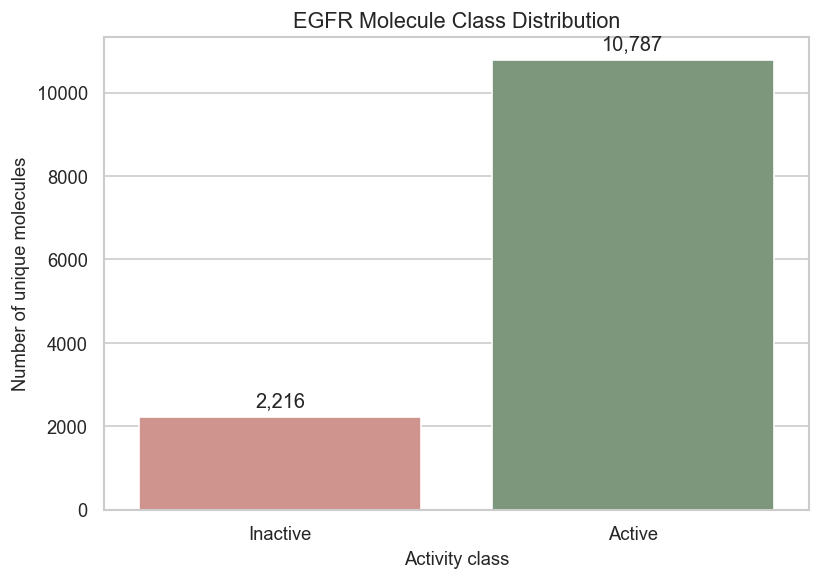

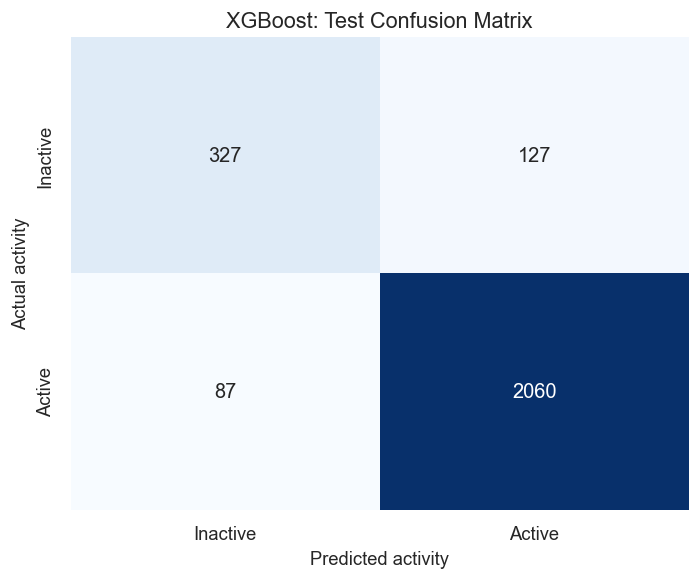

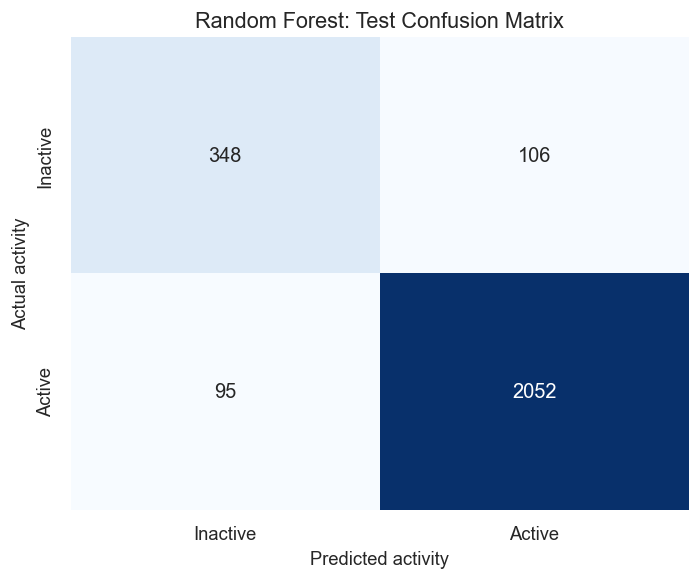

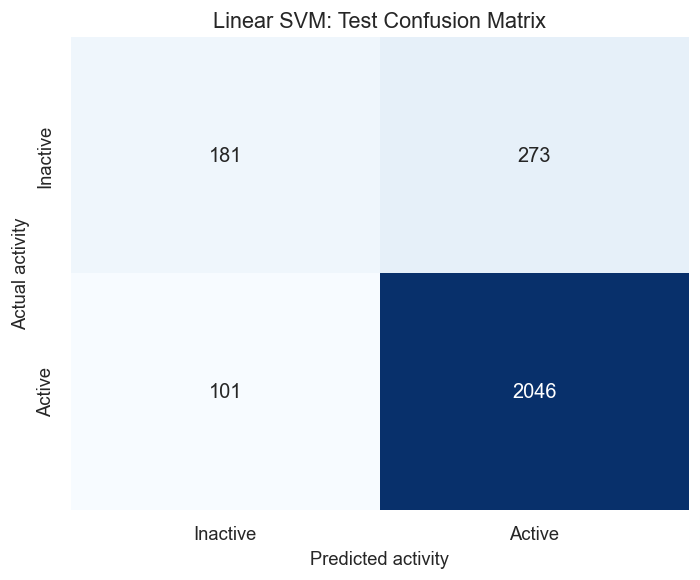

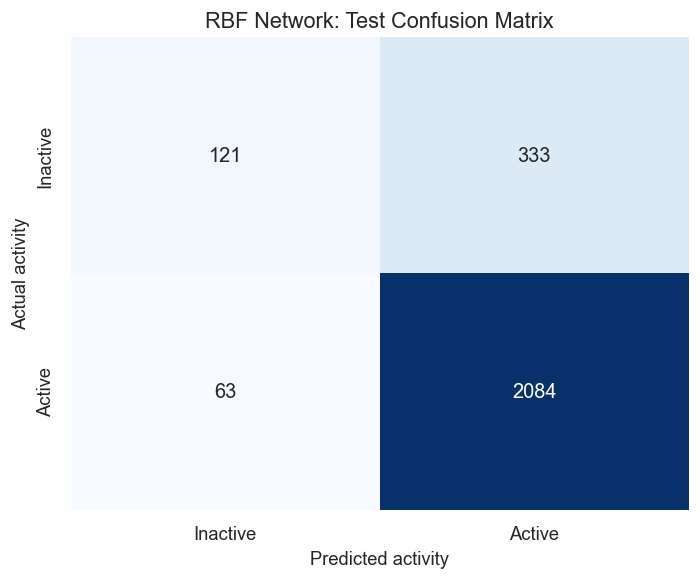

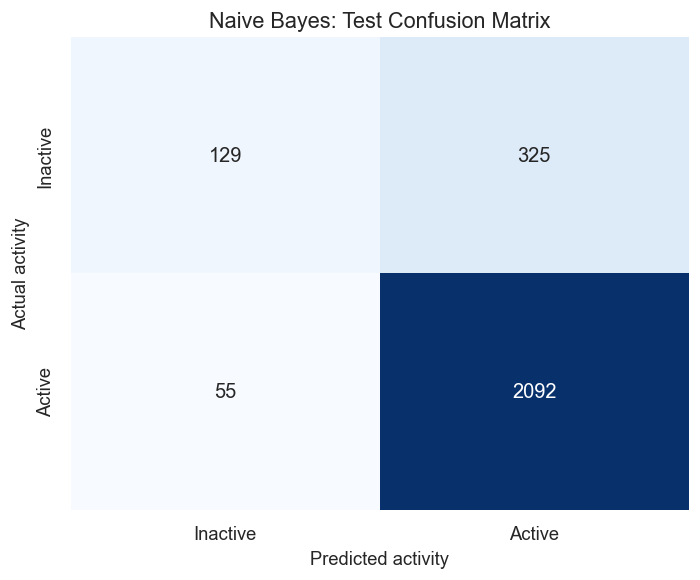

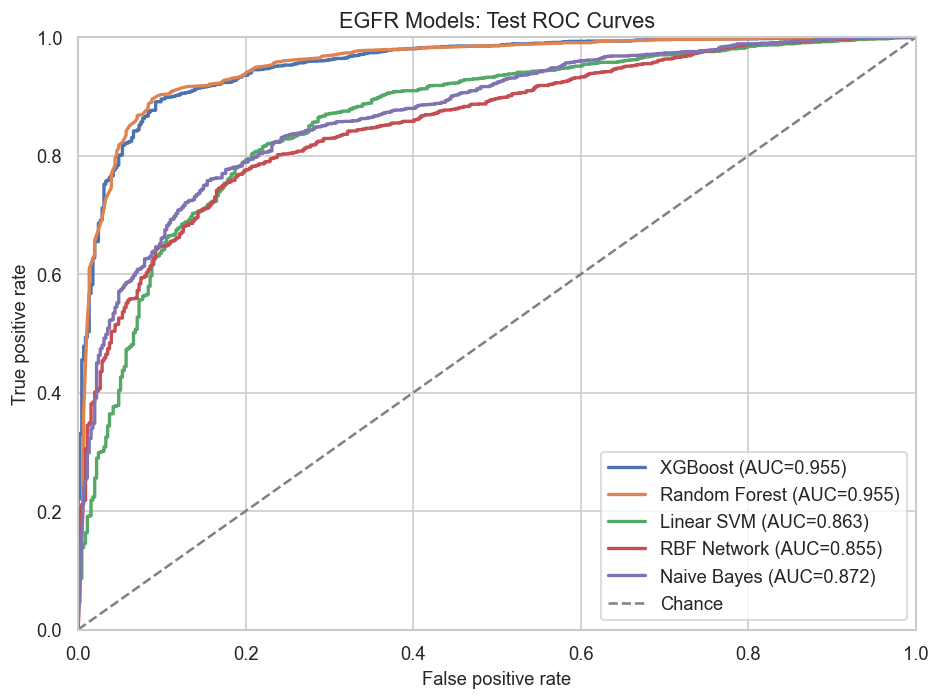

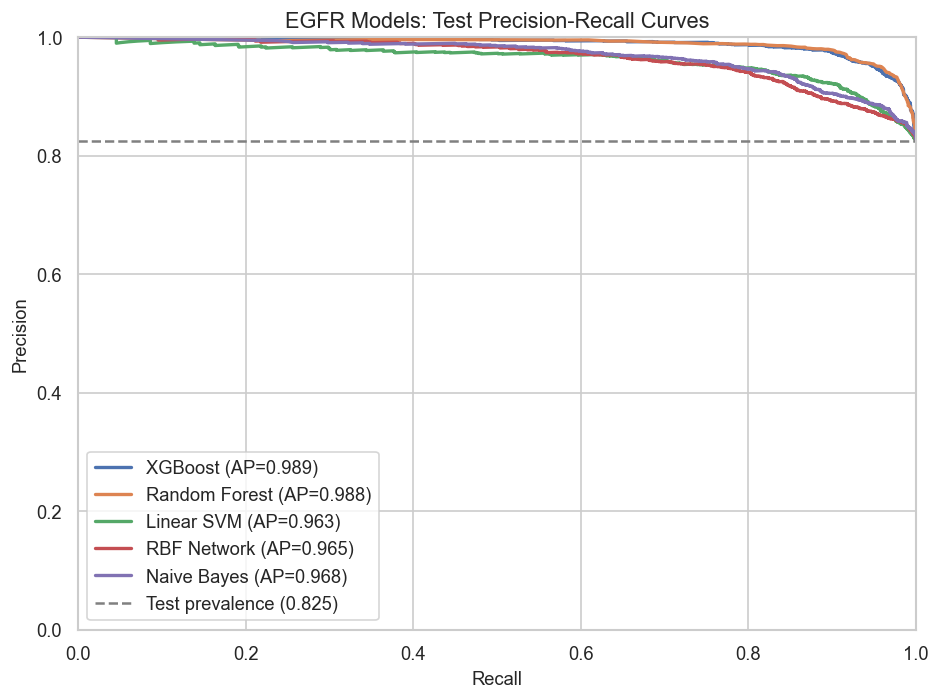

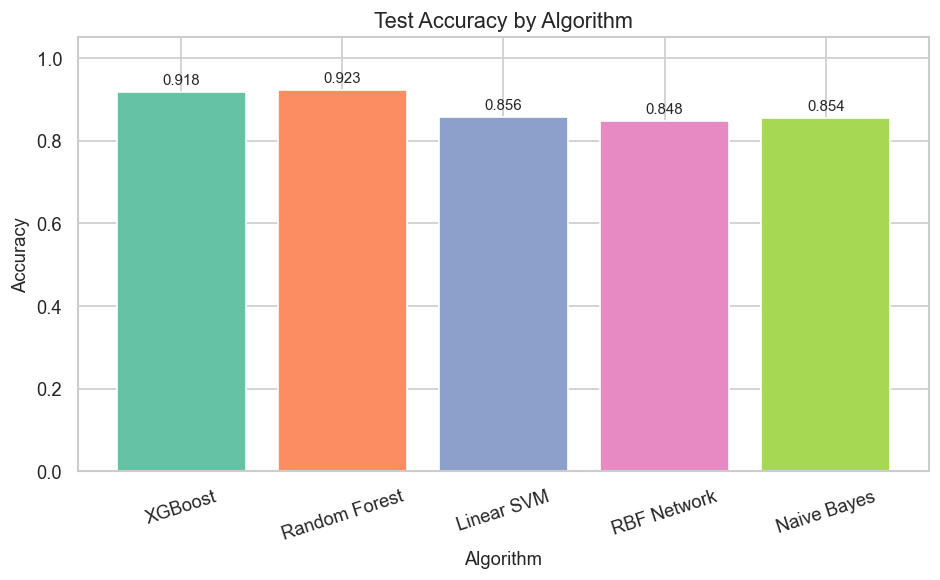

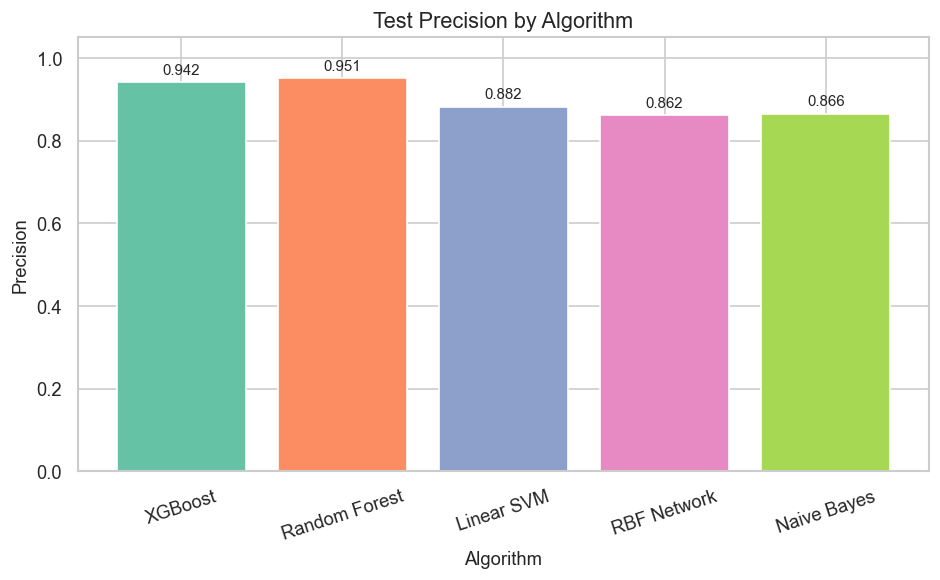

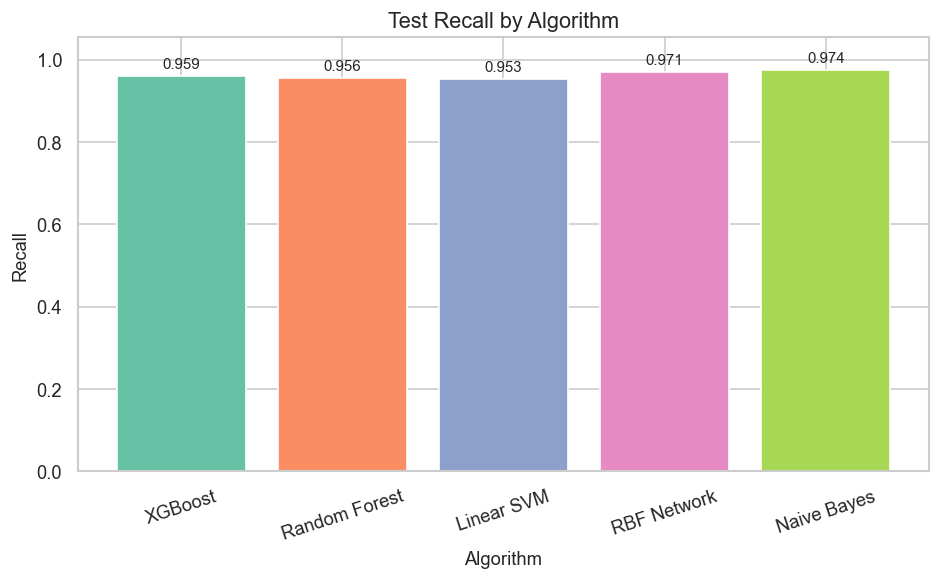

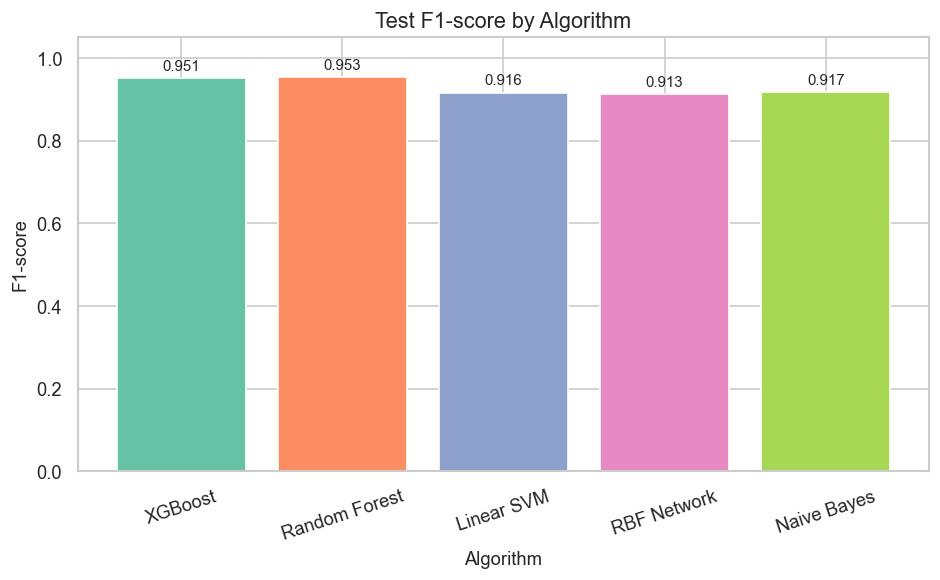

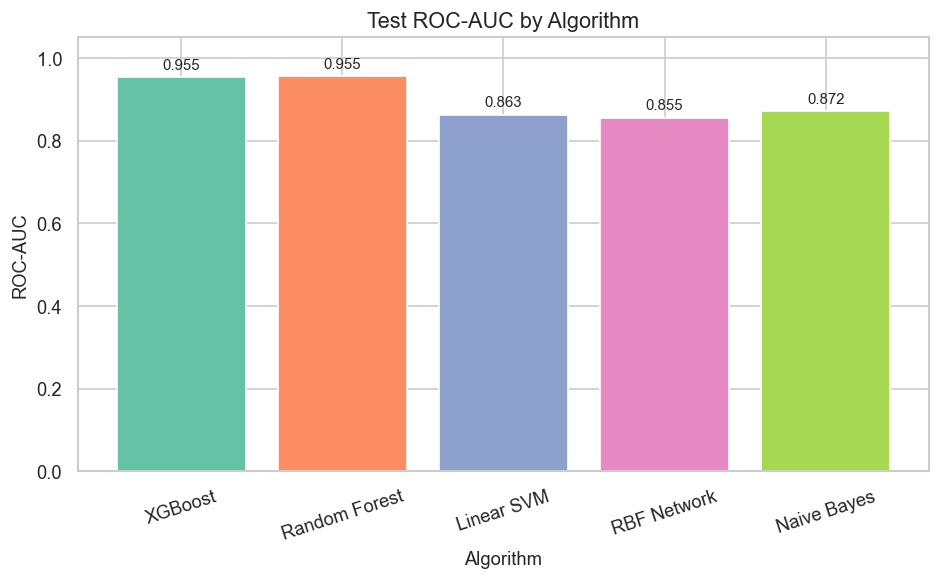

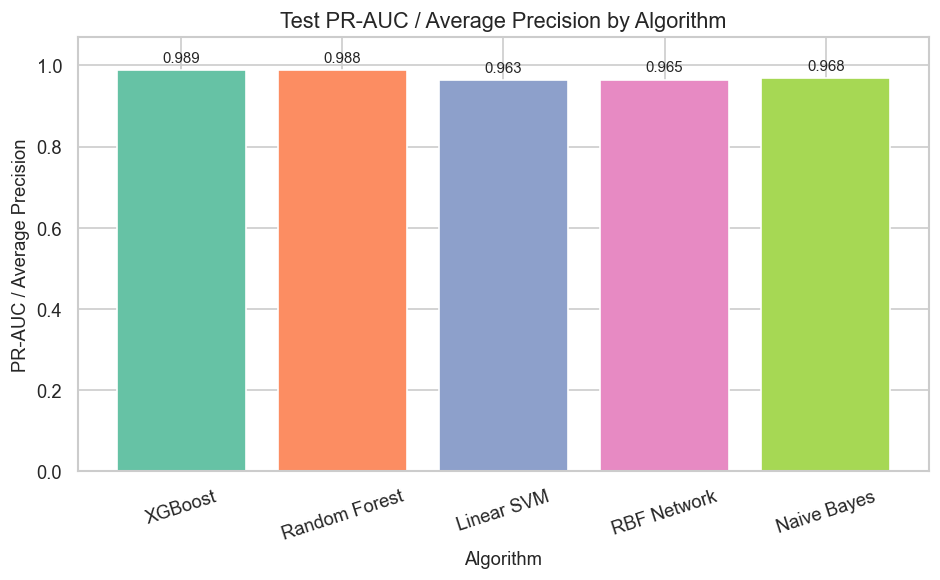

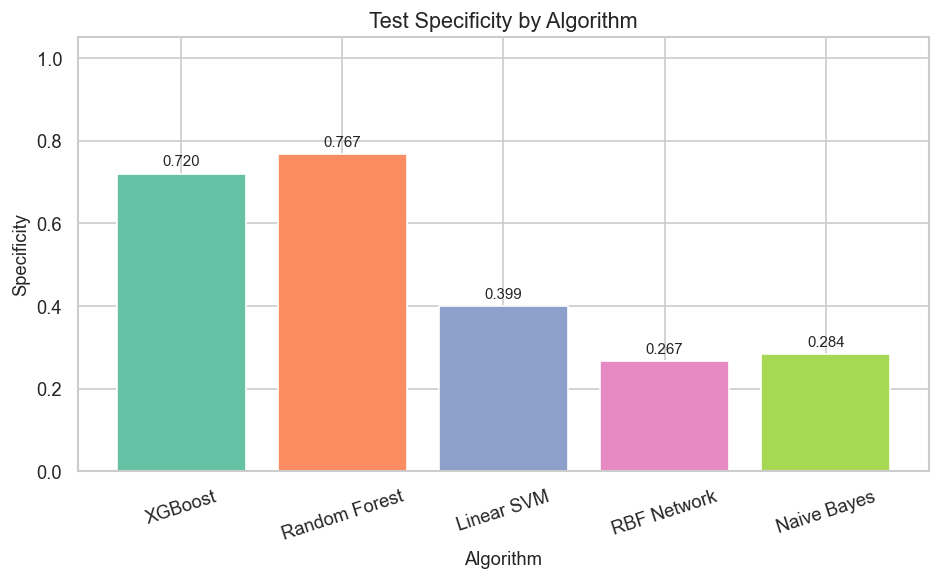

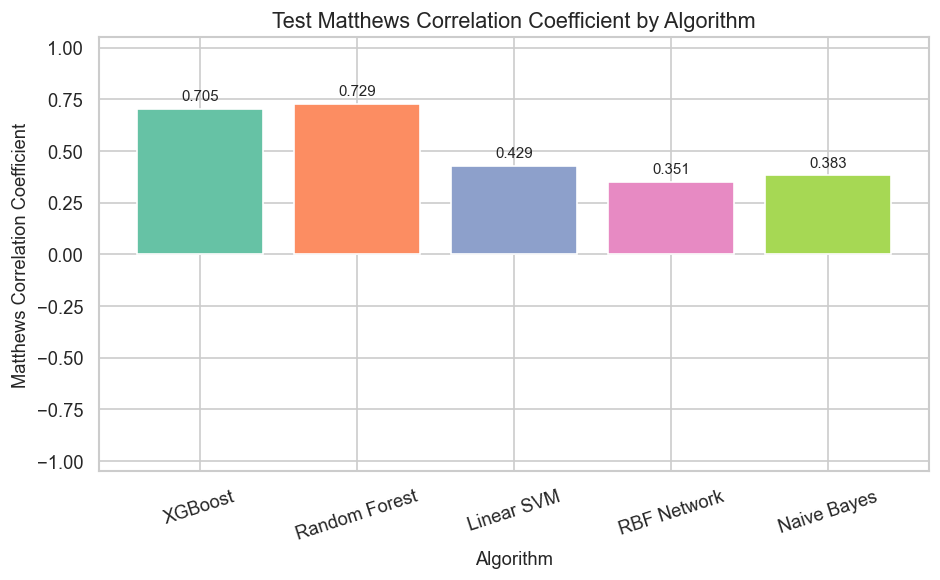

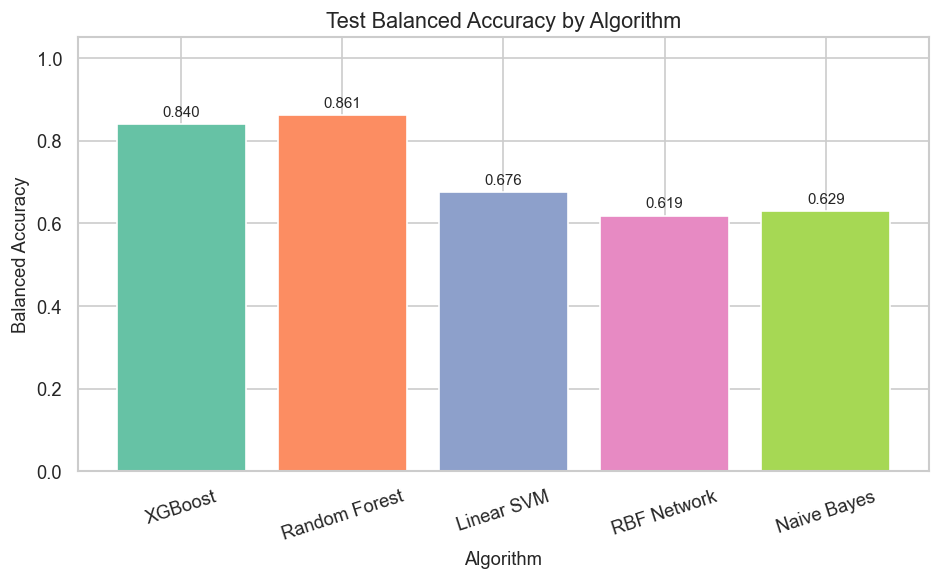

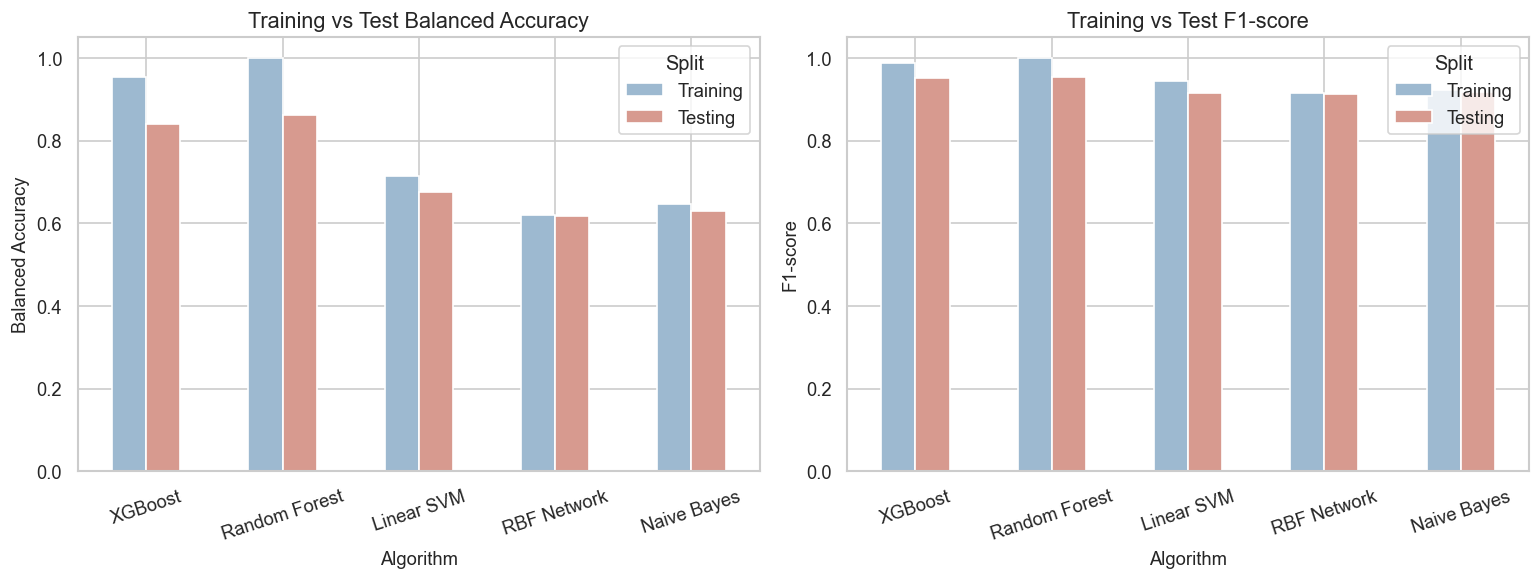

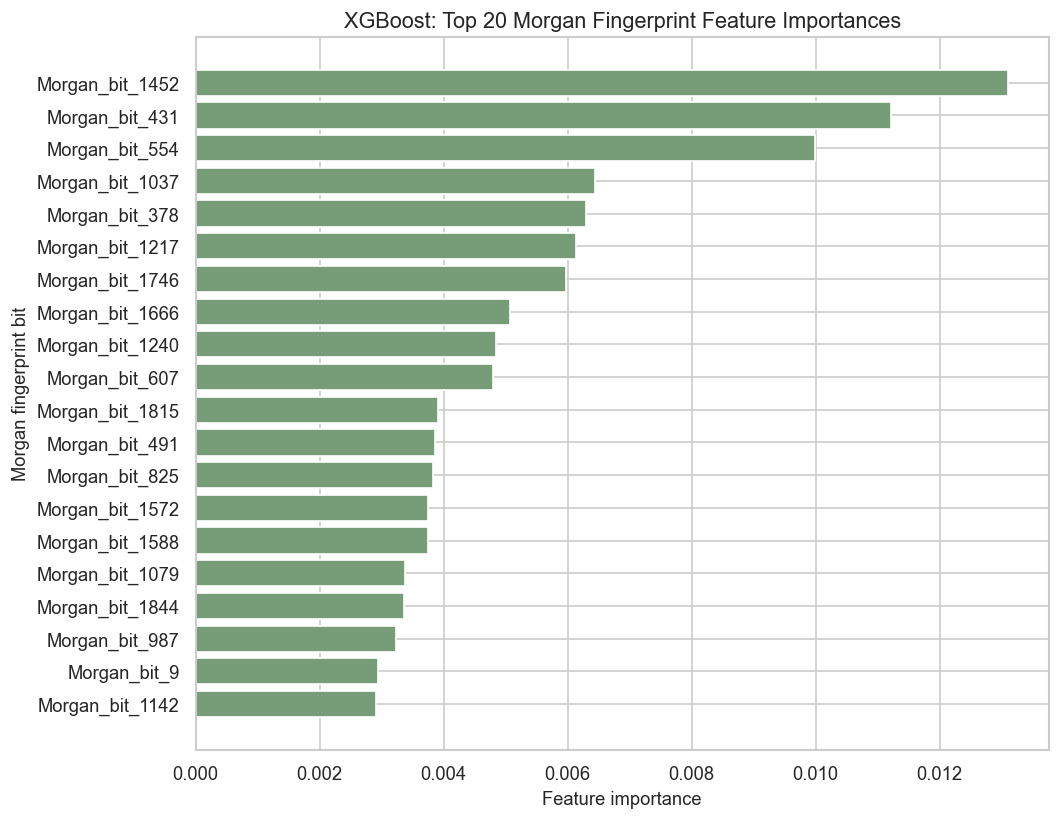

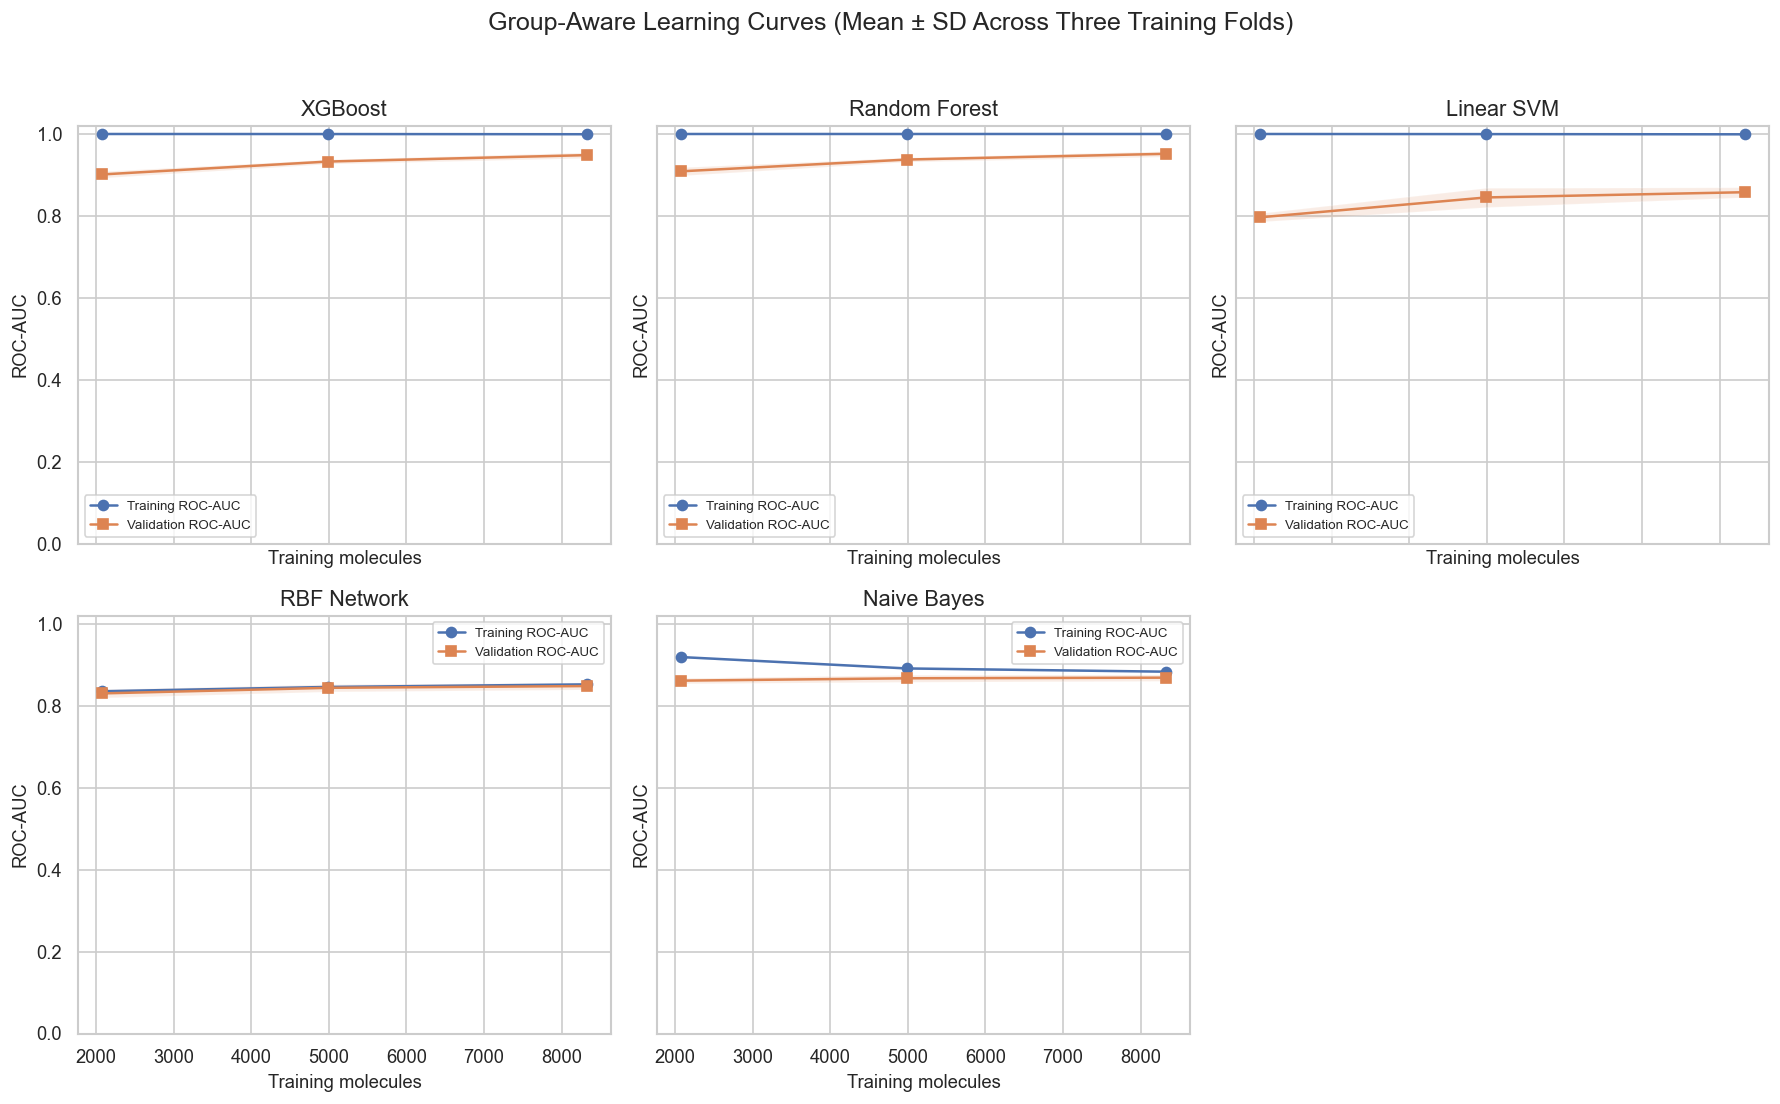

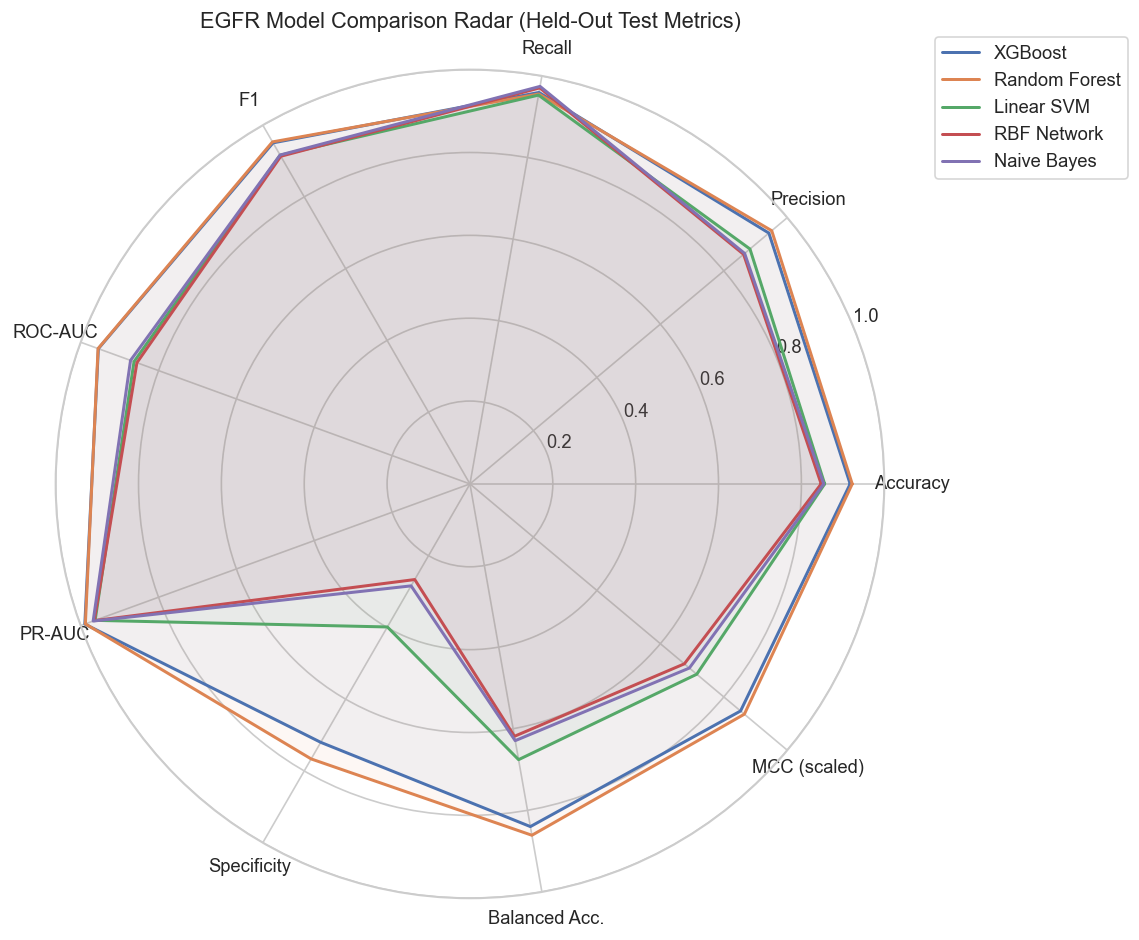

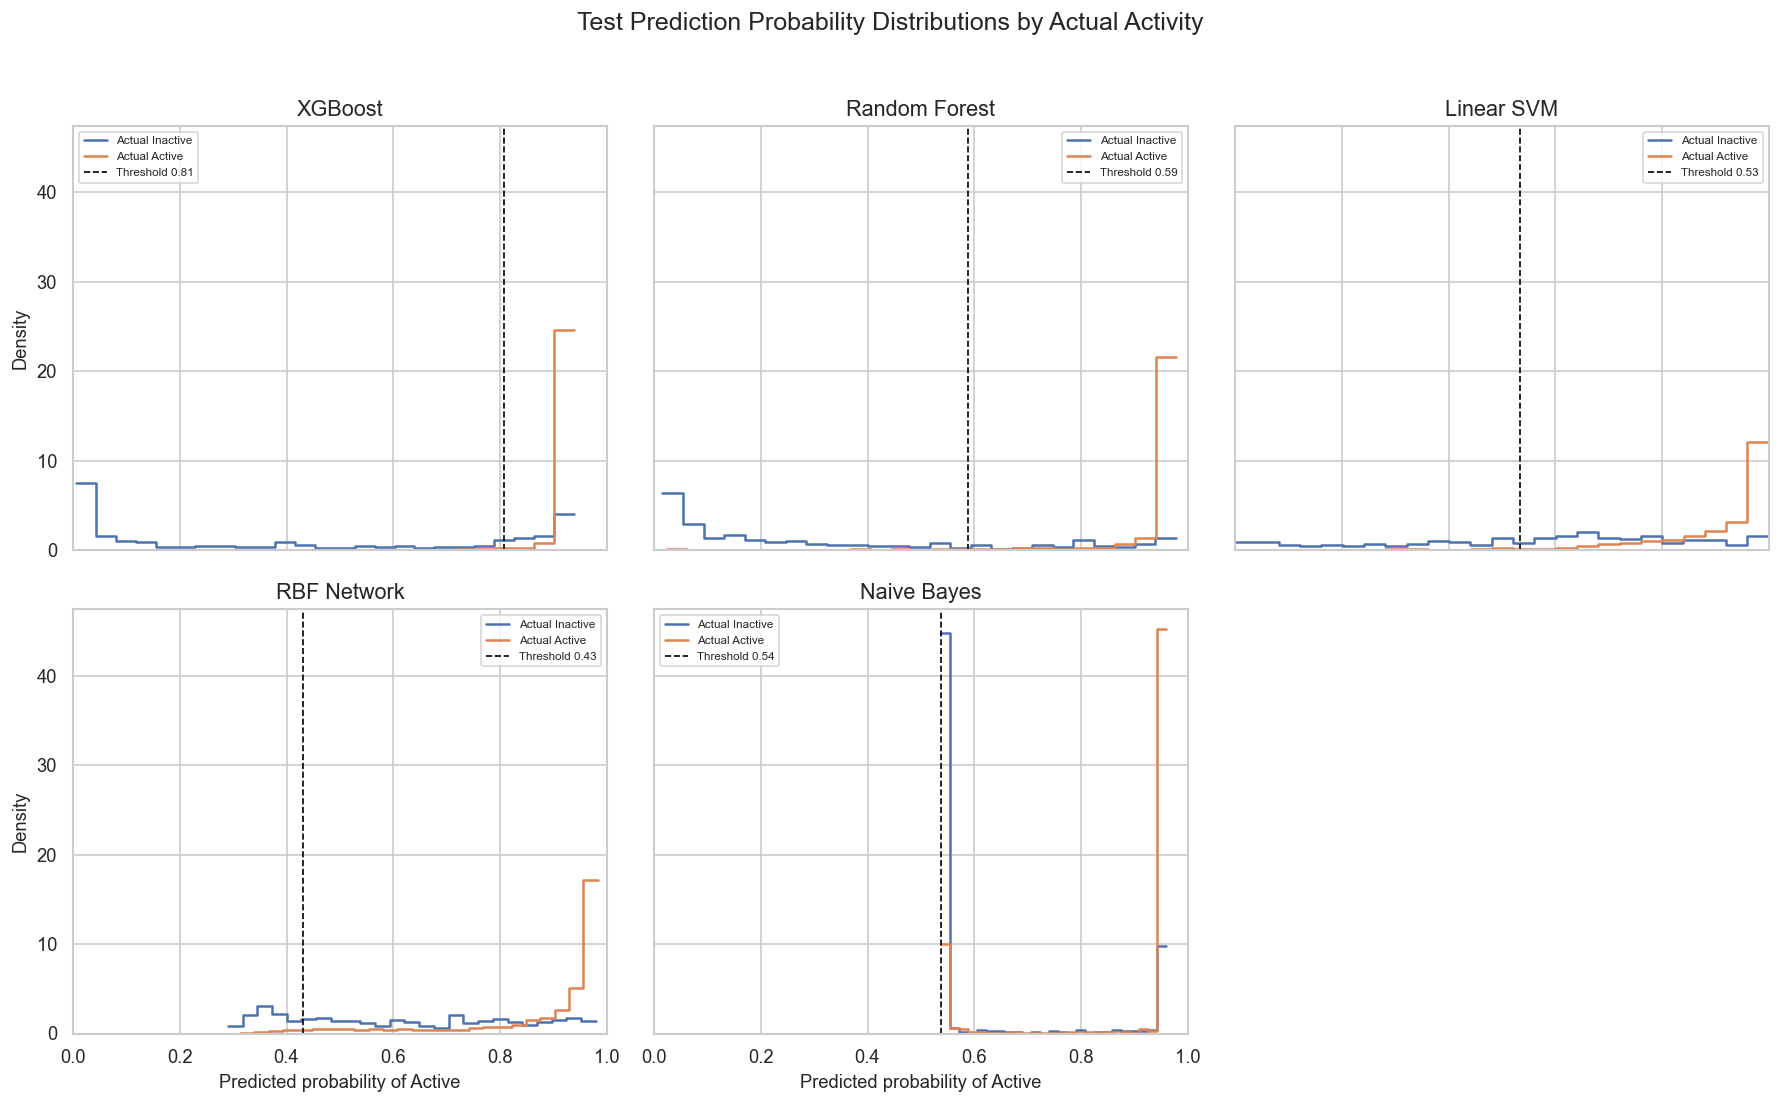

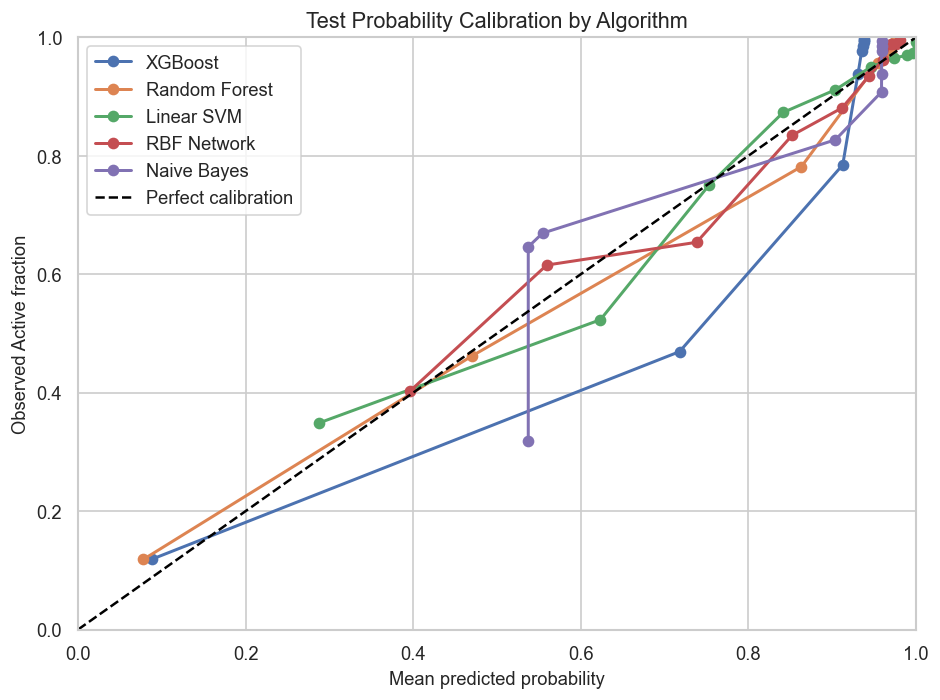

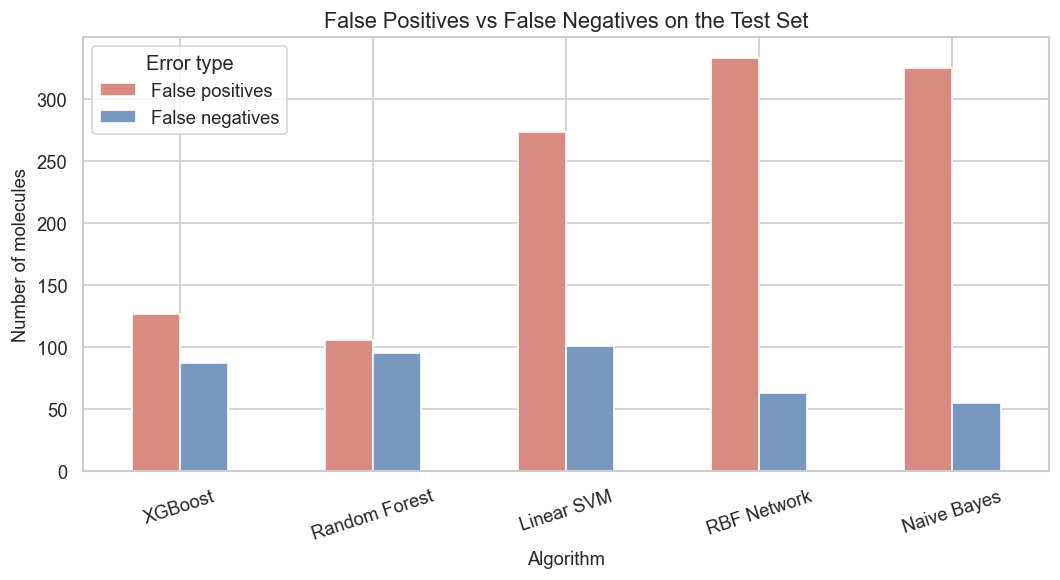

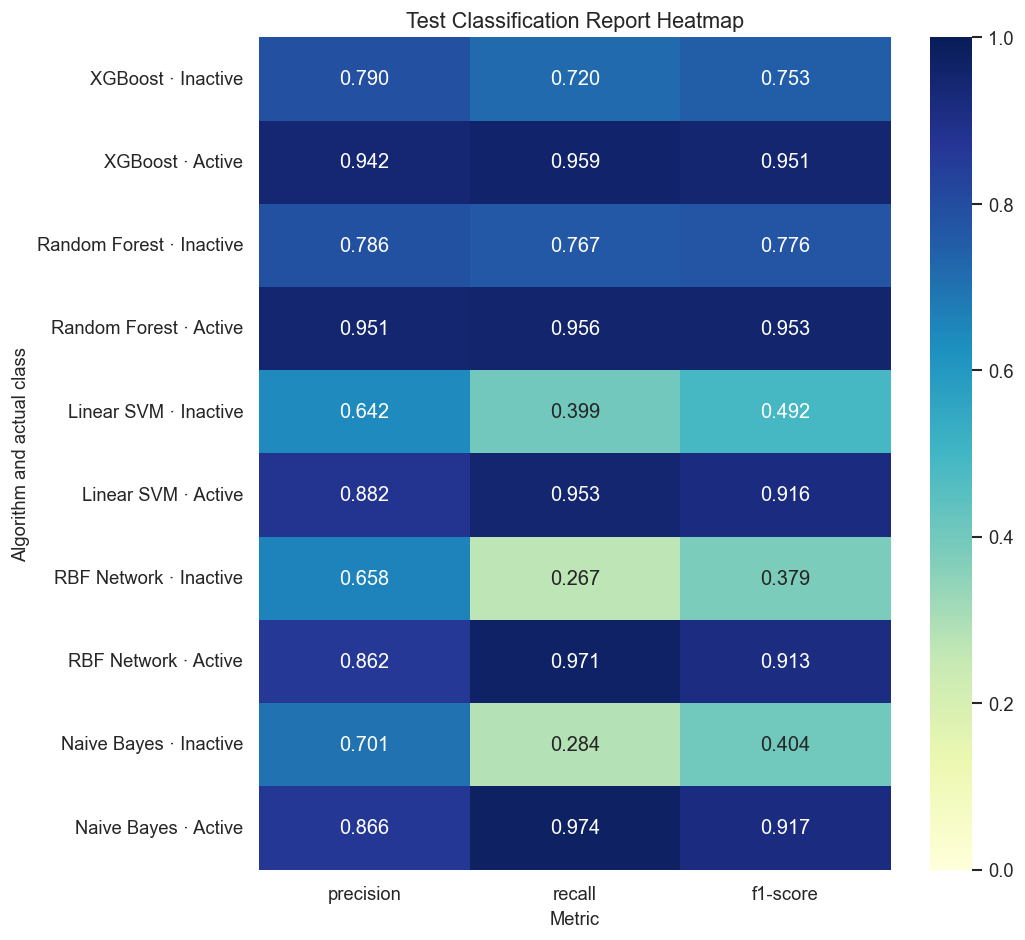

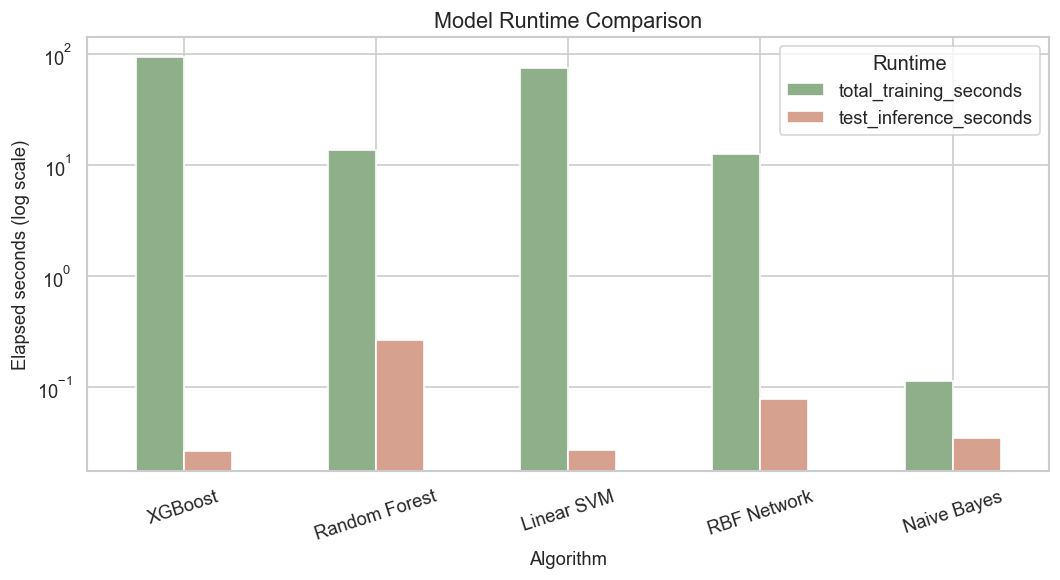

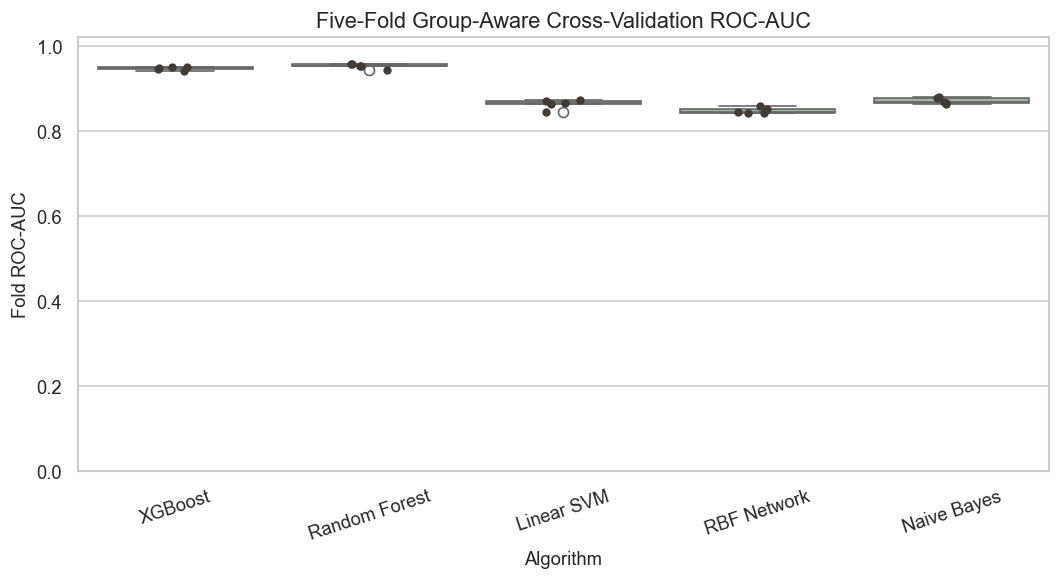

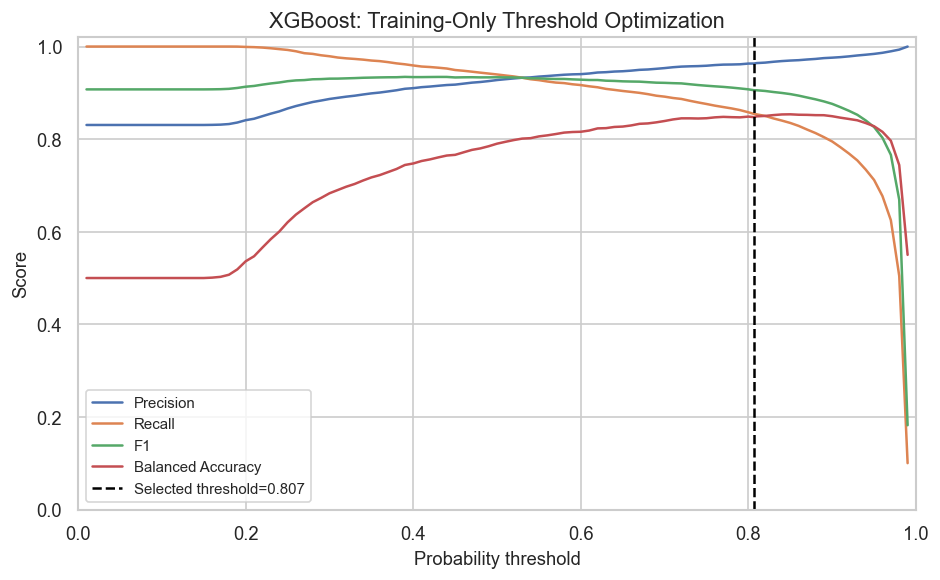

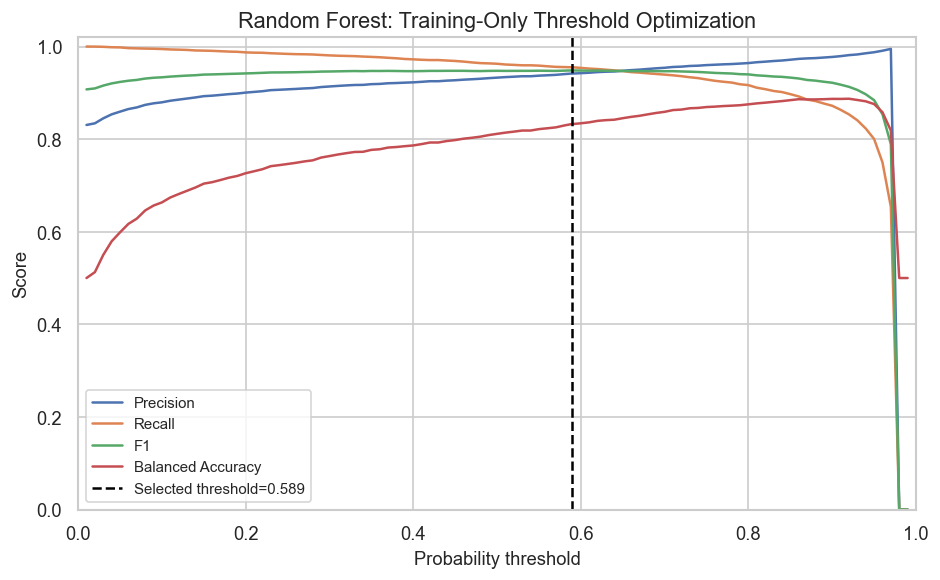

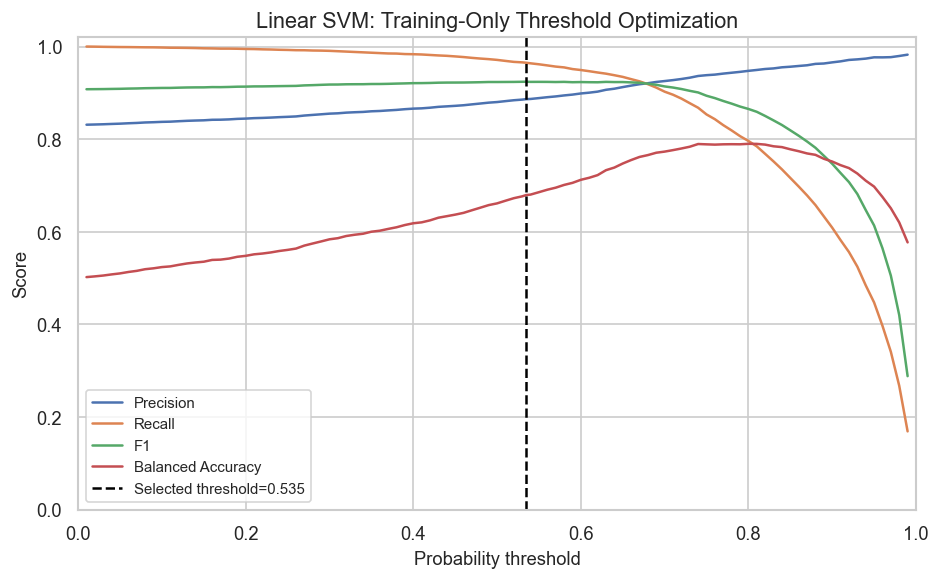

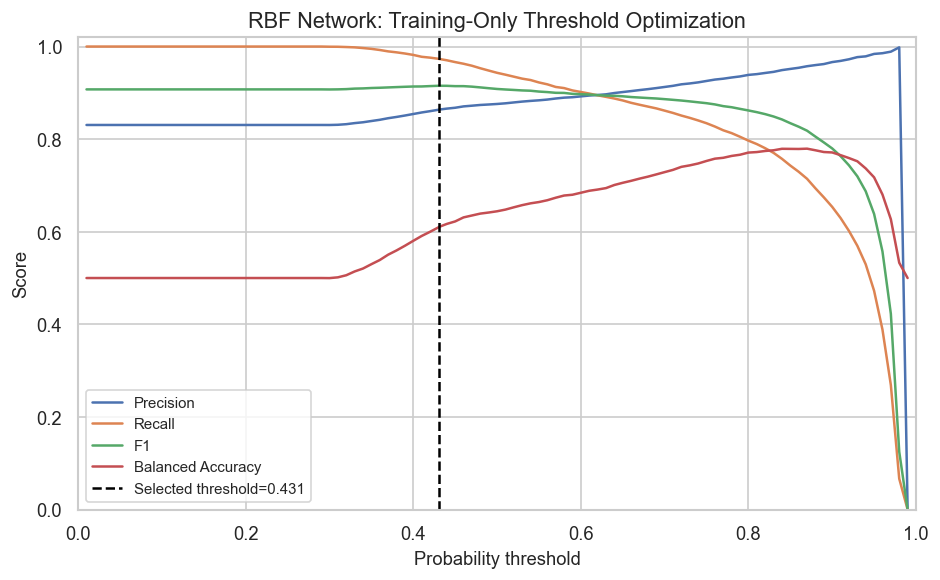

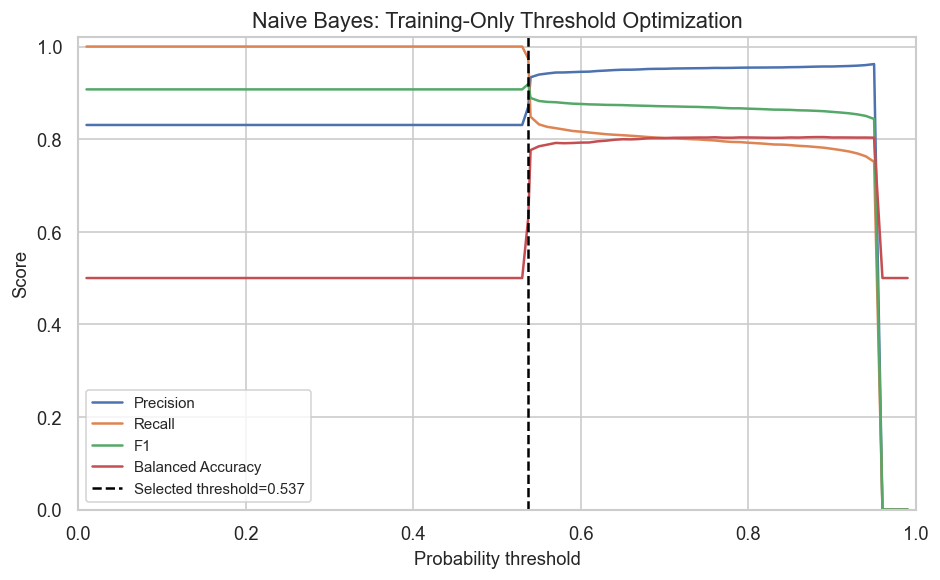

Generated and displayed 36 high-resolution PNG plots in /Users/m.saikarthikeya/Desktop/XGBioactiveNew/EGFR_model_evaluation_plots


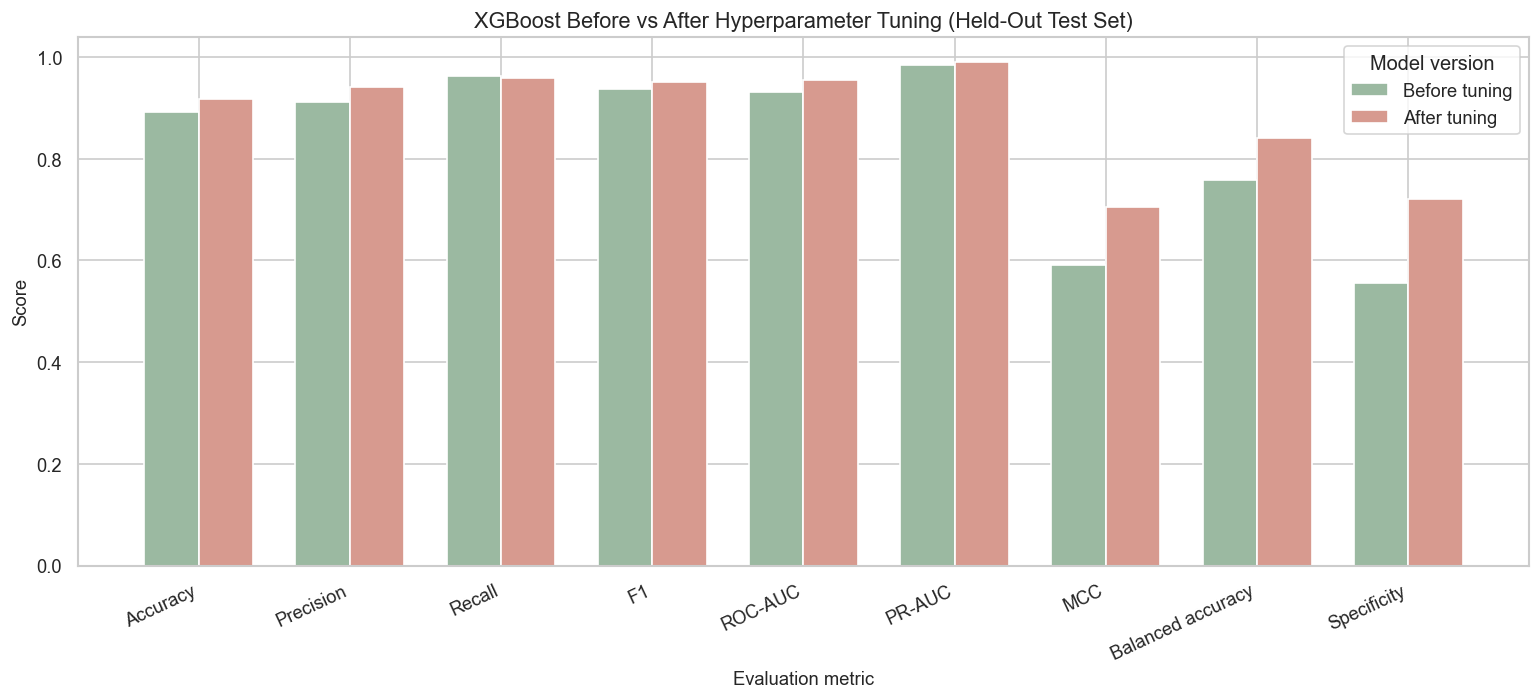

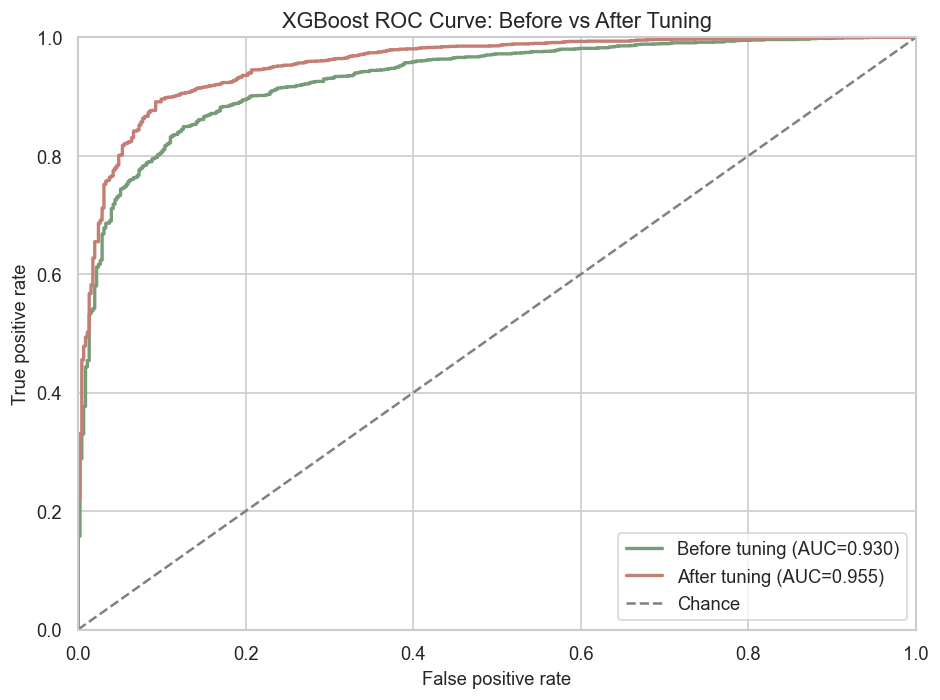

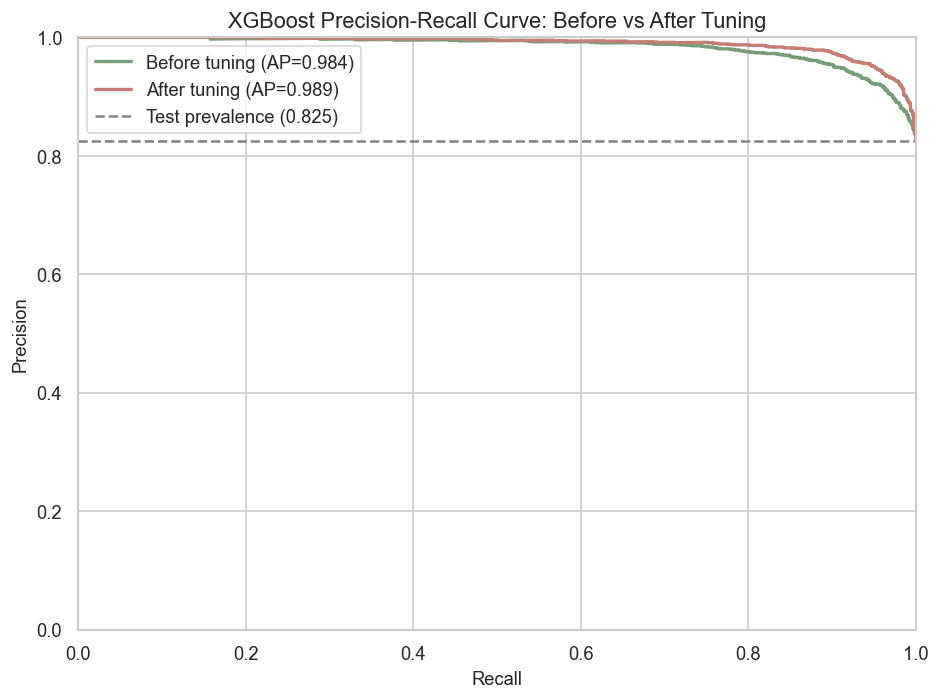

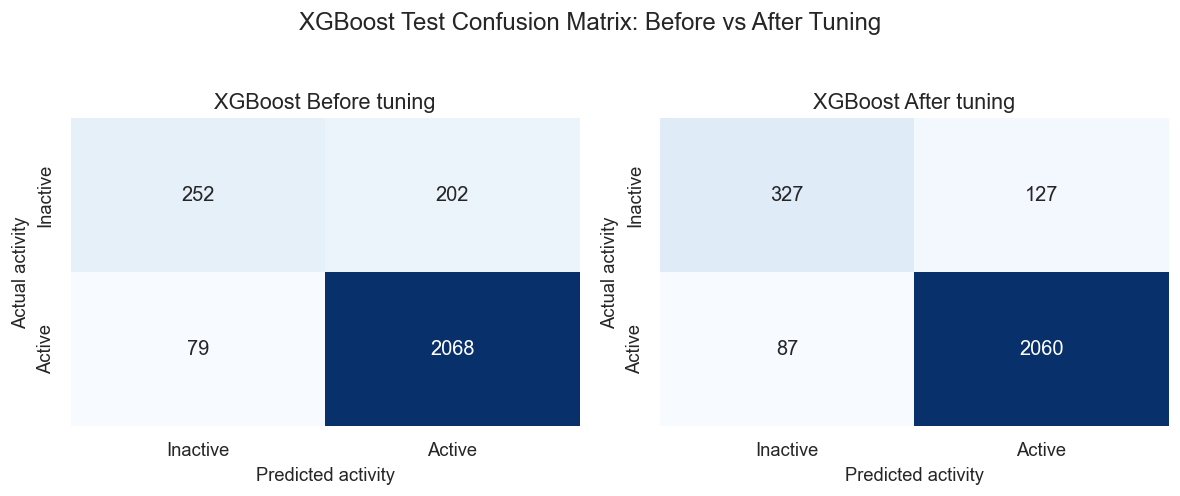

PosixPath('/Users/m.saikarthikeya/Desktop/XGBioactiveNew/EGFR_model_evaluation_plots/36_xgboost_before_after_confusion_matrices.png')

In [10]:
def save_and_show(filename):
    output_path = PLOT_DIR / filename
    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()
    return output_path

# 1. Class distribution from the canonicalized, unambiguous EGFR molecule dataset.
class_counts = df_model["label"].map({0: "Inactive", 1: "Active"}).value_counts().reindex(["Inactive", "Active"])
fig, ax = plt.subplots(figsize=(7, 5))
sns.barplot(x=class_counts.index, y=class_counts.values, hue=class_counts.index, legend=False, palette=["#D98C82", "#779C78"], ax=ax)
ax.set(title="EGFR Molecule Class Distribution", xlabel="Activity class", ylabel="Number of unique molecules")
for patch, value in zip(ax.patches, class_counts.values):
    ax.annotate(f"{value:,}", (patch.get_x() + patch.get_width()/2, patch.get_height()), ha="center", va="bottom", xytext=(0, 4), textcoords="offset points")
save_and_show("01_class_distribution.png")

# 2-6. Individual confusion matrices for all five test predictions.
for index, model_name in enumerate(MODEL_NAMES, start=2):
    predicted = (test_probabilities[model_name] >= thresholds[model_name]).astype(np.int8)
    cm = confusion_matrix(y_test, predicted, labels=[0, 1])
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["Inactive", "Active"], yticklabels=["Inactive", "Active"], ax=ax)
    ax.set(title=f"{model_name}: Test Confusion Matrix", xlabel="Predicted activity", ylabel="Actual activity")
    save_and_show(f"{index:02d}_confusion_matrix_{model_name.lower().replace(' ', '_')}.png")

# 7. Combined ROC curves on the untouched test set.
fig, ax = plt.subplots(figsize=(8, 6))
for model_name in MODEL_NAMES:
    fpr, tpr, _ = roc_curve(y_test, test_probabilities[model_name])
    auc_value = metrics.set_index("model").loc[model_name, "roc_auc"]
    ax.plot(fpr, tpr, linewidth=2, label=f"{model_name} (AUC={auc_value:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
ax.set(title="EGFR Models: Test ROC Curves", xlabel="False positive rate", ylabel="True positive rate", xlim=(0, 1), ylim=(0, 1))
ax.legend(loc="lower right")
save_and_show("07_combined_roc_curves.png")

# 8. Combined precision-recall curves on the untouched test set.
fig, ax = plt.subplots(figsize=(8, 6))
for model_name in MODEL_NAMES:
    precision_values, recall_values, _ = precision_recall_curve(y_test, test_probabilities[model_name])
    ap_value = metrics.set_index("model").loc[model_name, "pr_auc"]
    ax.plot(recall_values, precision_values, linewidth=2, label=f"{model_name} (AP={ap_value:.3f})")
ax.axhline(y=float(y_test.mean()), linestyle="--", color="gray", label=f"Test prevalence ({y_test.mean():.3f})")
ax.set(title="EGFR Models: Test Precision-Recall Curves", xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1))
ax.legend(loc="best")
save_and_show("08_combined_precision_recall_curves.png")

# 9-17. Individual comparison charts for all nine requested classification metrics.
metric_plot_specs = [
    ("accuracy", "Accuracy", 9),
    ("precision", "Precision", 10),
    ("recall", "Recall", 11),
    ("f1", "F1-score", 12),
    ("roc_auc", "ROC-AUC", 13),
    ("pr_auc", "PR-AUC / Average Precision", 14),
    ("specificity", "Specificity", 15),
    ("mcc", "Matthews Correlation Coefficient", 16),
    ("balanced_accuracy", "Balanced Accuracy", 17),
]
for metric_name, display_name, figure_number in metric_plot_specs:
    ordered = metrics.set_index("model").loc[MODEL_NAMES]
    fig, ax = plt.subplots(figsize=(8, 5))
    bars = ax.bar(MODEL_NAMES, ordered[metric_name], color=sns.color_palette("Set2", len(MODEL_NAMES)))
    ax.set(title=f"Test {display_name} by Algorithm", xlabel="Algorithm", ylabel=display_name)
    ax.set_ylim(min(-1.05, float(ordered[metric_name].min()) - 0.08) if metric_name == "mcc" else 0,
                max(1.05, float(ordered[metric_name].max()) + 0.08))
    ax.tick_params(axis="x", rotation=18)
    ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)
    save_and_show(f"{figure_number:02d}_{metric_name}_comparison.png")

# 18. Training-versus-test performance comparison using actual fitted-model predictions.
train_indexed = train_metrics.set_index("model").loc[MODEL_NAMES]
test_indexed = metrics.set_index("model").loc[MODEL_NAMES]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, metric_name, title in zip(axes, ["balanced_accuracy", "f1"], ["Balanced Accuracy", "F1-score"]):
    comparison = pd.DataFrame({"Training": train_indexed[metric_name], "Testing": test_indexed[metric_name]}, index=MODEL_NAMES)
    comparison.plot(kind="bar", ax=ax, color=["#9DB9D0", "#D79A8F"])
    ax.set(title=f"Training vs Test {title}", xlabel="Algorithm", ylabel=title, ylim=(0, 1.05))
    ax.tick_params(axis="x", rotation=18)
    ax.legend(title="Split")
save_and_show("18_training_vs_testing_performance.png")

# 19. Top 20 XGBoost Morgan-bit importances from the final training-only fitted model.
xgb_importance = pd.Series(final_models["XGBoost"].feature_importances_, index=feature_names, name="importance")
top_xgb_importance = xgb_importance.nlargest(20).sort_values()
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top_xgb_importance.index, top_xgb_importance.values, color="#779C78")
ax.set(title="XGBoost: Top 20 Morgan Fingerprint Feature Importances", xlabel="Feature importance", ylabel="Morgan fingerprint bit")
save_and_show("19_xgboost_top20_feature_importance.png")

# 20. Learning curves for all five algorithms, using group-stratified training folds.
learning_records = []
learning_sizes = [0.25, 0.60, 1.00]
for fold_number, (fold_train_idx, fold_valid_idx) in enumerate(cv_splits[:3], start=1):
    X_fold_valid, y_fold_valid = X_train[fold_valid_idx], y_train[fold_valid_idx]
    for fraction in learning_sizes:
        if fraction == 1.0:
            subset_idx = np.arange(len(fold_train_idx))
        else:
            subsampler = StratifiedShuffleSplit(n_splits=1, train_size=fraction, random_state=SEED + fold_number)
            subset_idx, _ = next(subsampler.split(np.zeros(len(fold_train_idx)), y_train[fold_train_idx]))
        fit_idx = fold_train_idx[subset_idx]
        for model_name in MODEL_NAMES:
            curve_model = clone(models[model_name])
            fit_with_balanced_weights(curve_model, model_name, X_train[fit_idx], y_train[fit_idx])
            train_curve_scores = raw_positive_score(curve_model, X_train[fit_idx])
            valid_curve_scores = raw_positive_score(curve_model, X_fold_valid)
            learning_records.append({
                "model": model_name,
                "fold": fold_number,
                "fraction": fraction,
                "training_molecules": len(fit_idx),
                "training_roc_auc": roc_auc_score(y_train[fit_idx], train_curve_scores),
                "validation_roc_auc": roc_auc_score(y_fold_valid, valid_curve_scores),
            })
learning_curves = pd.DataFrame(learning_records)
fig, axes = plt.subplots(2, 3, figsize=(15, 9), sharex=True, sharey=True)
for ax, model_name in zip(axes.flat, MODEL_NAMES):
    curve_data = learning_curves[learning_curves["model"] == model_name]
    summary = curve_data.groupby("fraction").agg(
        n=("training_molecules", "mean"),
        train_mean=("training_roc_auc", "mean"), train_std=("training_roc_auc", "std"),
        valid_mean=("validation_roc_auc", "mean"), valid_std=("validation_roc_auc", "std"),
    ).sort_values("n")
    ax.plot(summary["n"], summary["train_mean"], marker="o", label="Training ROC-AUC")
    ax.fill_between(summary["n"], summary["train_mean"]-summary["train_std"].fillna(0), summary["train_mean"]+summary["train_std"].fillna(0), alpha=0.15)
    ax.plot(summary["n"], summary["valid_mean"], marker="s", label="Validation ROC-AUC")
    ax.fill_between(summary["n"], summary["valid_mean"]-summary["valid_std"].fillna(0), summary["valid_mean"]+summary["valid_std"].fillna(0), alpha=0.15)
    ax.set(title=model_name, xlabel="Training molecules", ylabel="ROC-AUC")
    ax.set_ylim(0, 1.02)
    ax.legend(fontsize=8)
axes.flat[-1].axis("off")
fig.suptitle("Group-Aware Learning Curves (Mean ± SD Across Three Training Folds)", y=1.02, fontsize=15)
save_and_show("20_learning_curves_all_algorithms.png")

# 21. Radar plot comparing test metrics (MCC mapped linearly from [-1, 1] to [0, 1]).
radar_metrics = ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "specificity", "balanced_accuracy", "mcc"]
radar_labels = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC", "Specificity", "Balanced Acc.", "MCC (scaled)"]
angles = np.linspace(0, 2*np.pi, len(radar_metrics), endpoint=False).tolist()
angles += angles[:1]
fig, ax = plt.subplots(figsize=(9, 8), subplot_kw={"polar": True})
metrics_by_model = metrics.set_index("model")
for model_name in MODEL_NAMES:
    values = metrics_by_model.loc[model_name, radar_metrics].astype(float).tolist()
    values[-1] = (values[-1] + 1.0) / 2.0
    values += values[:1]
    ax.plot(angles, values, linewidth=1.8, label=model_name)
    ax.fill(angles, values, alpha=0.06)
ax.set_xticks(angles[:-1], radar_labels)
ax.set_ylim(0, 1)
ax.set_title("EGFR Model Comparison Radar (Held-Out Test Metrics)", pad=25)
ax.legend(loc="upper left", bbox_to_anchor=(1.05, 1.05))
save_and_show("21_model_comparison_radar.png")

# 22. Test positive-class probability distributions, separated by actual class.
fig, axes = plt.subplots(2, 3, figsize=(15, 9), sharex=True, sharey=True)
for ax, model_name in zip(axes.flat, MODEL_NAMES):
    sns.histplot(test_probabilities[model_name][y_test == 0], bins=25, stat="density", element="step", fill=False, label="Actual Inactive", ax=ax)
    sns.histplot(test_probabilities[model_name][y_test == 1], bins=25, stat="density", element="step", fill=False, label="Actual Active", ax=ax)
    ax.axvline(thresholds[model_name], color="black", linestyle="--", linewidth=1, label=f"Threshold {thresholds[model_name]:.2f}")
    ax.set(title=model_name, xlabel="Predicted probability of Active", ylabel="Density", xlim=(0, 1))
    ax.legend(fontsize=7)
axes.flat[-1].axis("off")
fig.suptitle("Test Prediction Probability Distributions by Actual Activity", y=1.02, fontsize=15)
save_and_show("22_prediction_probability_distributions.png")

# 23. Calibration curves on the untouched test set.
fig, ax = plt.subplots(figsize=(8, 6))
for model_name in MODEL_NAMES:
    observed_fraction, mean_probability = calibration_curve(
        y_test, test_probabilities[model_name], n_bins=10, strategy="quantile"
    )
    ax.plot(mean_probability, observed_fraction, marker="o", linewidth=1.8, label=model_name)
ax.plot([0, 1], [0, 1], linestyle="--", color="black", label="Perfect calibration")
ax.set(title="Test Probability Calibration by Algorithm", xlabel="Mean predicted probability", ylabel="Observed Active fraction", xlim=(0, 1), ylim=(0, 1))
ax.legend(loc="best")
save_and_show("23_calibration_curves.png")

# 24. False-positive versus false-negative comparison on test predictions.
error_table = metrics.set_index("model").loc[MODEL_NAMES, ["false_positive", "false_negative"]]
fig, ax = plt.subplots(figsize=(9, 5))
error_table.plot(kind="bar", ax=ax, color=["#D88B80", "#7898BD"])
ax.set(title="False Positives vs False Negatives on the Test Set", xlabel="Algorithm", ylabel="Number of molecules")
ax.tick_params(axis="x", rotation=18)
ax.legend(title="Error type", labels=["False positives", "False negatives"])
save_and_show("24_false_positive_vs_false_negative.png")

# 25. Classification report heatmap for both classes and every model.
report_rows = []
for model_name in MODEL_NAMES:
    predicted = (test_probabilities[model_name] >= thresholds[model_name]).astype(np.int8)
    report = classification_report(y_test, predicted, labels=[0, 1], output_dict=True, zero_division=0)
    for class_id, class_name in [(0, "Inactive"), (1, "Active")]:
        class_report = report[str(class_id)]
        report_rows.append({
            "model_class": f"{model_name} · {class_name}",
            "precision": class_report["precision"],
            "recall": class_report["recall"],
            "f1-score": class_report["f1-score"],
        })
classification_report_table = pd.DataFrame(report_rows).set_index("model_class")
fig, ax = plt.subplots(figsize=(9, 8))
sns.heatmap(classification_report_table, annot=True, fmt=".3f", cmap="YlGnBu", vmin=0, vmax=1, ax=ax)
ax.set(title="Test Classification Report Heatmap", xlabel="Metric", ylabel="Algorithm and actual class")
save_and_show("25_classification_report_heatmap.png")

# 26. Training and test-inference runtimes measured during this notebook run.
fig, ax = plt.subplots(figsize=(9, 5))
runtime_plot = runtime_table.set_index("model").loc[MODEL_NAMES, ["total_training_seconds", "test_inference_seconds"]]
runtime_plot.plot(kind="bar", ax=ax, color=["#8FAE8A", "#D6A28F"])
ax.set(title="Model Runtime Comparison", xlabel="Algorithm", ylabel="Elapsed seconds (log scale)", yscale="log")
ax.tick_params(axis="x", rotation=18)
ax.legend(title="Runtime")
save_and_show("26_model_runtime_comparison.png")

# 27. Cross-validation ROC-AUC score distribution from the five training-only group folds.
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=cv_scores, x="model", y="roc_auc", order=MODEL_NAMES, color="#9BB9A1", ax=ax)
sns.stripplot(data=cv_scores, x="model", y="roc_auc", order=MODEL_NAMES, color="#423B35", size=5, ax=ax)
ax.set(title="Five-Fold Group-Aware Cross-Validation ROC-AUC", xlabel="Algorithm", ylabel="Fold ROC-AUC", ylim=(0, 1.02))
ax.tick_params(axis="x", rotation=18)
save_and_show("27_cross_validation_score_comparison.png")

# 28-32. Training-only threshold optimization curves for each model.
threshold_curve_records = []
for index, model_name in enumerate(MODEL_NAMES, start=28):
    probabilities = oof_probabilities[model_name]
    candidate_thresholds = np.unique(np.concatenate([
        np.linspace(0.01, 0.99, 99), np.array([thresholds[model_name]])
    ]))
    curve_rows = []
    for threshold in candidate_thresholds:
        predicted = probabilities >= threshold
        tn, fp, fn, tp = confusion_matrix(y_train, predicted, labels=[0, 1]).ravel()
        curve_rows.append({
            "threshold": threshold,
            "precision": precision_score(y_train, predicted, zero_division=0),
            "recall": recall_score(y_train, predicted, zero_division=0),
            "f1": f1_score(y_train, predicted, zero_division=0),
            "balanced_accuracy": balanced_accuracy_score(y_train, predicted),
        })
    curve_data = pd.DataFrame(curve_rows)
    curve_data["model"] = model_name
    threshold_curve_records.append(curve_data)
    fig, ax = plt.subplots(figsize=(8, 5))
    for metric_name in ["precision", "recall", "f1", "balanced_accuracy"]:
        ax.plot(curve_data["threshold"], curve_data[metric_name], label=metric_name.replace("_", " ").title())
    ax.axvline(thresholds[model_name], color="black", linestyle="--", label=f"Selected threshold={thresholds[model_name]:.3f}")
    ax.set(title=f"{model_name}: Training-Only Threshold Optimization", xlabel="Probability threshold", ylabel="Score", xlim=(0, 1), ylim=(0, 1.02))
    ax.legend(loc="best", fontsize=9)
    save_and_show(f"{index:02d}_threshold_optimization_{model_name.lower().replace(' ', '_')}.png")
threshold_curves = pd.concat(threshold_curve_records, ignore_index=True)

print(f"Generated and displayed {len(list(PLOT_DIR.glob('*.png')))} high-resolution PNG plots in {PLOT_DIR}")

# Before-versus-after XGBoost comparison; both versions use the identical held-out test set.
before_after_metrics = ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "mcc", "balanced_accuracy", "specificity"]
before_after_labels = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC", "MCC", "Balanced accuracy", "Specificity"]
fig, ax = plt.subplots(figsize=(13, 6))
comparison_positions = np.arange(len(before_after_metrics))
bar_width = 0.36
before_values = [baseline_xgb_test_metrics[name] for name in before_after_metrics]
after_values = [tuned_xgb_test_metrics[name] for name in before_after_metrics]
ax.bar(comparison_positions - bar_width/2, before_values, bar_width, label="Before tuning", color="#9BB9A1")
ax.bar(comparison_positions + bar_width/2, after_values, bar_width, label="After tuning", color="#D79A8F")
ax.set(title="XGBoost Before vs After Hyperparameter Tuning (Held-Out Test Set)", xlabel="Evaluation metric", ylabel="Score")
ax.set_xticks(comparison_positions, before_after_labels, rotation=25, ha="right")
ax.legend(title="Model version")
ax.axhline(0, color="black", linewidth=0.6)
save_and_show("33_xgboost_before_after_metrics.png")

fig, ax = plt.subplots(figsize=(8, 6))
for version, probabilities, color in [
    ("Before tuning", baseline_xgb_test_probabilities, "#779C78"),
    ("After tuning", test_probabilities["XGBoost"], "#C47E73"),
]:
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    auc = roc_auc_score(y_test, probabilities)
    ax.plot(fpr, tpr, linewidth=2, color=color, label=f"{version} (AUC={auc:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
ax.set(title="XGBoost ROC Curve: Before vs After Tuning", xlabel="False positive rate", ylabel="True positive rate", xlim=(0, 1), ylim=(0, 1))
ax.legend(loc="lower right")
save_and_show("34_xgboost_before_after_roc.png")

fig, ax = plt.subplots(figsize=(8, 6))
for version, probabilities, color in [
    ("Before tuning", baseline_xgb_test_probabilities, "#779C78"),
    ("After tuning", test_probabilities["XGBoost"], "#C47E73"),
]:
    precision_values, recall_values, _ = precision_recall_curve(y_test, probabilities)
    ap = average_precision_score(y_test, probabilities)
    ax.plot(recall_values, precision_values, linewidth=2, color=color, label=f"{version} (AP={ap:.3f})")
ax.axhline(y=float(y_test.mean()), linestyle="--", color="gray", label=f"Test prevalence ({y_test.mean():.3f})")
ax.set(title="XGBoost Precision-Recall Curve: Before vs After Tuning", xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1))
ax.legend(loc="best")
save_and_show("35_xgboost_before_after_precision_recall.png")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, version, probabilities in zip(axes, ["Before tuning", "After tuning"], [baseline_xgb_test_probabilities, test_probabilities["XGBoost"]]):
    predicted = (probabilities >= (baseline_xgb_threshold if version == "Before tuning" else tuned_xgb_threshold)).astype(np.int8)
    cm = confusion_matrix(y_test, predicted, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["Inactive", "Active"], yticklabels=["Inactive", "Active"], ax=ax)
    ax.set(title=f"XGBoost {version}", xlabel="Predicted activity", ylabel="Actual activity")
fig.suptitle("XGBoost Test Confusion Matrix: Before vs After Tuning", y=1.03)
save_and_show("36_xgboost_before_after_confusion_matrices.png")


## 10. Model comparison

The comparison table contains all nine requested held-out metrics. Cross-validation scores are summarized separately; the top cross-validation mean ROC-AUC is used to designate a **CV-selected candidate**. The test set is reserved for final reporting, not model selection. Test ROC-AUC and PR-AUC are also exported as a compact table.

In [11]:
cv_summary = cv_scores.groupby("model").agg(
    mean_cv_roc_auc=("roc_auc", "mean"),
    sd_cv_roc_auc=("roc_auc", "std"),
    mean_cv_pr_auc=("pr_auc", "mean"),
    sd_cv_pr_auc=("pr_auc", "std"),
).reindex(MODEL_NAMES)
comparison_table = metrics.set_index("model").join(cv_summary).reset_index()
auc_results = comparison_table[["model", "roc_auc", "pr_auc", "mean_cv_roc_auc", "sd_cv_roc_auc", "mean_cv_pr_auc", "sd_cv_pr_auc"]].copy()
print("Algorithm comparison (test metrics and training-only CV summary):")
display(comparison_table.style.format({column: "{:.4f}" for column in comparison_table.select_dtypes(include="number").columns}))
best_model_name = str(cv_summary["mean_cv_roc_auc"].idxmax())
print(f"CV-selected candidate by mean group-CV ROC-AUC: {best_model_name}")
print("Its held-out test metrics are descriptive final evaluation results:")
display(metrics.set_index("model").loc[[best_model_name]])

Algorithm comparison (test metrics and training-only CV summary):


,model,threshold,accuracy,precision,recall,specificity,f1,roc_auc,pr_auc,mcc,balanced_accuracy,true_negative,false_positive,false_negative,true_positive,mean_cv_roc_auc,sd_cv_roc_auc,mean_cv_pr_auc,sd_cv_pr_auc
0,XGBoost,0.8069,0.9177,0.9419,0.9595,0.7203,0.9506,0.9545,0.9893,0.7053,0.8399,327.0000,127.0000,87.0000,2060.0000,0.9469,0.0038,0.9881,0.0011
1,Random Forest,0.5891,0.9227,0.9509,0.9558,0.7665,0.9533,0.9553,0.9879,0.7293,0.8611,348.0000,106.0000,95.0000,2052.0000,0.9530,0.0055,0.9893,0.0017
2,Linear SVM,0.5346,0.8562,0.8823,0.9530,0.3987,0.9163,0.8629,0.9628,0.4293,0.6758,181.0000,273.0000,101.0000,2046.0000,0.8635,0.0116,0.9622,0.0053
3,RBF Network,0.4307,0.8478,0.8622,0.9707,0.2665,0.9132,0.8555,0.9650,0.3511,0.6186,121.0000,333.0000,63.0000,2084.0000,0.8476,0.0070,0.9634,0.0035
4,Naive Bayes,0.5372,0.8539,0.8655,0.9744,0.2841,0.9167,0.8719,0.9679,0.3827,0.6293,129.0000,325.0000,55.0000,2092.0000,0.8706,0.0076,0.9688,0.0037


CV-selected candidate by mean group-CV ROC-AUC: Random Forest
Its held-out test metrics are descriptive final evaluation results:


,threshold,accuracy,precision,recall,specificity,f1,roc_auc,pr_auc,mcc,balanced_accuracy,true_negative,false_positive,false_negative,true_positive
model,,,,,,,,,,,,,,
Random Forest,0.589091,0.922722,0.95088,0.955752,0.76652,0.95331,0.955257,0.987902,0.729318,0.861136,348,106,95,2052


## 11. Best-model analysis

Inspect the CV-selected model's threshold, test confusion counts, errors, and (for XGBoost) top fingerprint-bit features. Morgan bit indices are fingerprint features, not direct chemical names; a bit can encode multiple environments due to hashing.

In [12]:
best_metrics = metrics.set_index("model").loc[best_model_name]
print(f"CV-selected model: {best_model_name}")
print(f"Training-only F1-optimal threshold: {thresholds[best_model_name]:.4f}")
print(f"Test ROC-AUC: {best_metrics['roc_auc']:.4f}; test PR-AUC: {best_metrics['pr_auc']:.4f}")
print(
    "Test confusion counts — "
    f"TN={int(best_metrics['true_negative'])}, FP={int(best_metrics['false_positive'])}, "
    f"FN={int(best_metrics['false_negative'])}, TP={int(best_metrics['true_positive'])}"
)
if best_model_name == "XGBoost":
    display(top_xgb_importance.sort_values(ascending=False).to_frame("importance"))
else:
    print("The XGBoost feature-importance plot is provided separately, as required.")

CV-selected model: Random Forest
Training-only F1-optimal threshold: 0.5891
Test ROC-AUC: 0.9553; test PR-AUC: 0.9879
Test confusion counts — TN=348, FP=106, FN=95, TP=2052
The XGBoost feature-importance plot is provided separately, as required.


## 12. Model and result saving

Save every fitted classifier with its training-only probability calibrator and decision threshold. Save the XGBoost model at the requested filename, separate pickle files for all other algorithms, model metadata/configuration, complete metrics, ROC-AUC/PR-AUC results, CV fold scores, threshold-curve data, feature importances, and per-molecule test predictions/probabilities.

In [13]:
MODEL_FILENAMES = {
    "XGBoost": "egfr_xgboost_model.pkl",
    "Random Forest": "egfr_random_forest_model.pkl",
    "Linear SVM": "egfr_linear_svm_model.pkl",
    "RBF Network": "egfr_rbf_network_model.pkl",
    "Naive Bayes": "egfr_naive_bayes_model.pkl",
}
model_paths = {}
baseline_xgb_model_path = MODEL_DIR / "egfr_xgboost_model_before_tuning.pkl"
joblib.dump({"estimator": baseline_xgb_model, "calibrator": baseline_xgb_calibrator,
             "threshold": baseline_xgb_threshold, "feature_config": FEATURE_CONFIG,
             "model_name": "XGBoost baseline"}, baseline_xgb_model_path)
for model_name in MODEL_NAMES:
    model_bundle = {
        "estimator": final_models[model_name],
        "calibrator": calibrators[model_name],
        "threshold": thresholds[model_name],
        "feature_config": FEATURE_CONFIG,
        "model_name": model_name,
    }
    model_path = MODEL_DIR / MODEL_FILENAMES[model_name]
    joblib.dump(model_bundle, model_path)
    model_paths[model_name] = str(model_path.relative_to(PROJECT_ROOT))

metrics_path = PROJECT_ROOT / "EGFR_model_metrics.csv"
auc_path = PROJECT_ROOT / "EGFR_roc_auc_pr_auc_results.csv"
predictions_path = PROJECT_ROOT / "EGFR_test_predictions_and_probabilities.csv"
cv_path = ARTIFACT_DIR / "cross_validation_fold_scores.csv"
threshold_path = ARTIFACT_DIR / "threshold_optimization_curves.csv"
runtime_path = ARTIFACT_DIR / "model_runtime.csv"
feature_importance_path = ARTIFACT_DIR / "xgboost_feature_importance.csv"
feature_config_path = ARTIFACT_DIR / "feature_configuration.json"
best_params_path = ARTIFACT_DIR / "xgboost_best_hyperparameters.json"
search_results_path = ARTIFACT_DIR / "xgboost_randomized_search_results.csv"
before_after_path = PROJECT_ROOT / "EGFR_xgboost_before_after_metrics.csv"
metadata_path = ARTIFACT_DIR / "model_metadata.json"

metrics.to_csv(metrics_path, index=False)
xgb_before_after.to_csv(before_after_path, index=False)
xgb_search_results.to_csv(search_results_path, index=False)
with best_params_path.open("w", encoding="utf-8") as file:
    json.dump({"search_metric": "average_precision", "best_cv_average_precision": float(xgb_search.best_score_),
               "best_search_parameters": best_xgb_search_params,
               "early_stopping_rounds_selected": selected_boosting_rounds,
               "final_parameters": optimized_xgb_params,
               "training_only_threshold": tuned_xgb_threshold,
               "search_elapsed_seconds": xgb_search_seconds}, file, indent=2)
auc_results.to_csv(auc_path, index=False)
test_predictions.to_csv(predictions_path, index=False)
cv_scores.to_csv(cv_path, index=False)
threshold_curves.to_csv(threshold_path, index=False)
runtime_table.to_csv(runtime_path, index=False)
xgb_importance.sort_values(ascending=False).rename_axis("feature").to_frame().to_csv(feature_importance_path)
with feature_config_path.open("w", encoding="utf-8") as file:
    json.dump(FEATURE_CONFIG, file, indent=2)

try:
    import sklearn
    import xgboost
    import rdkit
    package_versions = {
        "python": platform.python_version(),
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "scikit_learn": sklearn.__version__,
        "xgboost": xgboost.__version__,
        "rdkit": rdkit.__version__,
        "matplotlib": plt.matplotlib.__version__,
        "seaborn": sns.__version__,
    }
except Exception as error:
    package_versions = {"python": platform.python_version(), "version_collection_error": str(error)}

metadata = {
    "xgboost_tuning": {"method": "RandomizedSearchCV", "search_metric": "average_precision",
                       "best_cv_average_precision": float(xgb_search.best_score_),
                       "best_search_parameters": best_xgb_search_params,
                       "early_stopping_rounds_selected": selected_boosting_rounds,
                       "final_parameters": optimized_xgb_params,
                       "before_tuning_test_metrics": baseline_xgb_test_metrics,
                       "after_tuning_test_metrics": tuned_xgb_test_metrics},
    "project": "Bioactive Molecule Prediction",
    "target": TARGET_NAME,
    "target_uniprot": TARGET_UNIPROT,
    "dataset": str(DATA_PATH.relative_to(PROJECT_ROOT)),
    "input_record_count": int(len(df_source)),
    "invalid_smiles_removed": invalid_smiles_count,
    "conflicting_canonical_structures_removed": int(len(conflicting_groups)),
    "retained_unique_molecules": int(len(df_model)),
    "class_counts": {"Inactive": int((y == 0).sum()), "Active": int((y == 1).sum())},
    "test_size": int(len(test_idx)),
    "test_fraction": TEST_FRACTION,
    "random_seed": SEED,
    "feature_config": FEATURE_CONFIG,
    "thresholds_selected_from_training_oof": thresholds,
    "cv_selected_candidate": best_model_name,
    "model_files": model_paths,
    "package_versions": package_versions,
}
with metadata_path.open("w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=2)

print("Saved model files:")
for model_name, model_path in model_paths.items():
    print(f"  {model_name}: {model_path}")
print("Saved result files:")
for output_path in [metrics_path, auc_path, predictions_path, cv_path, threshold_path,
                    runtime_path, feature_importance_path, feature_config_path, metadata_path,
                    best_params_path, search_results_path, before_after_path, baseline_xgb_model_path,
                    canonical_dataset_path]:
    print(f"  {output_path.relative_to(PROJECT_ROOT)}")
print(f"Saved {len(list(PLOT_DIR.glob('*.png')))} PNG plots at 300 DPI to {PLOT_DIR.relative_to(PROJECT_ROOT)}/")

Saved model files:
  XGBoost: EGFR_model_artifacts/models/egfr_xgboost_model.pkl
  Random Forest: EGFR_model_artifacts/models/egfr_random_forest_model.pkl
  Linear SVM: EGFR_model_artifacts/models/egfr_linear_svm_model.pkl
  RBF Network: EGFR_model_artifacts/models/egfr_rbf_network_model.pkl
  Naive Bayes: EGFR_model_artifacts/models/egfr_naive_bayes_model.pkl
Saved result files:
  EGFR_model_metrics.csv
  EGFR_roc_auc_pr_auc_results.csv
  EGFR_test_predictions_and_probabilities.csv
  EGFR_model_artifacts/cross_validation_fold_scores.csv
  EGFR_model_artifacts/threshold_optimization_curves.csv
  EGFR_model_artifacts/model_runtime.csv
  EGFR_model_artifacts/xgboost_feature_importance.csv
  EGFR_model_artifacts/feature_configuration.json
  EGFR_model_artifacts/model_metadata.json
  EGFR_model_artifacts/xgboost_best_hyperparameters.json
  EGFR_model_artifacts/xgboost_randomized_search_results.csv
  EGFR_xgboost_before_after_metrics.csv
  EGFR_model_artifacts/models/egfr_xgboost_model_befo

## 13. Conclusion

This notebook creates an end-to-end, group-aware EGFR benchmark with five specified algorithms and a training-only threshold/calibration workflow. Interpret model rankings alongside class imbalance, PR-AUC, calibration, false-positive/false-negative counts, and the difference between training and held-out performance. Results are specific to the included data and split; they do not establish clinical efficacy or prospective performance.

Re-run all cells from the top to rebuild the plots, models, metadata, metrics, and test prediction files. The `EGFR_model_evaluation_plots/` folder contains each displayed figure as a 300-DPI PNG.

XGBoost tuning uses the training partition only. The before/after table and plots compare predictions on the same untouched test fold. A better tuned XGBoost result is not guaranteed; interpret the measured outcome alongside the other four algorithms and training-CV versus test metrics.